# Fragment-intensity diagnostics



In [2]:
from pathlib import Path
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'refac':
    ROOT = ROOT.parent
if not (ROOT / 'train_deep.py').is_file():
    raise RuntimeError('Run from the project root or refac directory.')
if Path(sys.prefix).resolve() != (ROOT / '.venv').resolve():
    raise RuntimeError('Select the project .venv notebook kernel.')
sys.path.insert(0, str(ROOT))
import common as c

VALIDATION_FILE = ROOT / 'refac' / 'clean_spectra_val_split.parquet'
CHECKPOINTS = {'Model A': 'refac/checkpoints/pipeline_20261014T225616_24d21fa2.pt'}
ACQUISITION_METHODS = None
PRIMARY_MODEL = 'Model A'
FAILURE_THRESHOLD = 0.5
MIN_GROUP_N = 30
BOOTSTRAP_REPLICATES = 500
SEED = 1312
BATCH_SIZE = 256
CHARGES = (2, 3, 4)
MOD_CLASSES = ('Unmodified', 'UNIMOD:35', 'UNIMOD:4', 'UNIMOD:35 + UNIMOD:4', 'Other modification')
COLORS = {2: '#007f86', 3: '#c65036', 4: '#6256a5'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Validation input:', VALIDATION_FILE)
print('Set CHECKPOINTS to trusted train_deep .pt files before inference.')

Validation input: /Users/fridolin.karger/dev/sommer/refac/clean_spectra_val_split.parquet
Set CHECKPOINTS to trusted train_deep .pt files before inference.


## Validation data and inspection axes


In [ ]:
import pyarrow.parquet as pq

split_labels = pq.read_table(VALIDATION_FILE, columns=['split']).column('split').to_pylist()
if not split_labels or set(split_labels) != {'val'}:
    raise ValueError('Input must contain validation rows only; mixed splits are forbidden.')
spectra = pd.read_parquet(VALIDATION_FILE)
assert spectra['split'].eq('val').all()
display(spectra.groupby(['frag', 'precursor_charge']).size().rename('n').to_frame())
if ACQUISITION_METHODS is not None:
    unknown_methods = set(ACQUISITION_METHODS) - set(spectra['frag'])
    if unknown_methods:
        raise ValueError(f'Unknown acquisition labels: {unknown_methods}')
    spectra = spectra[spectra['frag'].isin(ACQUISITION_METHODS)].copy()
spectra = spectra[spectra['precursor_charge'].isin(CHARGES)].copy()
spectra = spectra.sort_values(['raw_file', 'scan_number']).reset_index(drop=True)
if spectra.empty:
    raise ValueError('No validation spectra remain after filtering.')
print('Repeated raw-file/scan pairs:', int(spectra.duplicated(['raw_file', 'scan_number']).sum()))
spectra['spectrum_id'] = np.arange(len(spectra))
spectra['tokens'] = spectra['peptide_sequence'].map(c.parse_peptide)
if any(''.join(tokens) != sequence for tokens, sequence in zip(spectra['tokens'], spectra['peptide_sequence'])):
    raise ValueError('Peptide annotations could not be parsed without information loss.')
spectra['peptide_length'] = spectra['tokens'].map(len)
spectra['bare_sequence'] = spectra['tokens'].map(lambda tokens: ''.join(token[0] for token in tokens))
if not spectra['peptide_length'].between(2, c.MAX_PEPTIDE_LEN).all():
    raise ValueError('Peptide lengths exceed the trained vector representation.')
unknown_tokens = {token for tokens in spectra['tokens'] for token in tokens} - set(c.TOKEN_TO_IDX)
if unknown_tokens:
    raise ValueError(f'Unsupported model tokens: {unknown_tokens}')

def modification_class(tokens):
    codes = {int(code) for token in tokens for code in re.findall(r'UNIMOD:(\d+)', token)}
    if not codes:
        return 'Unmodified'
    if codes == {35}:
        return 'UNIMOD:35'
    if codes == {4}:
        return 'UNIMOD:4'
    if codes == {4, 35}:
        return 'UNIMOD:35 + UNIMOD:4'
    return 'Other modification'

spectra['mod_class'] = spectra['tokens'].map(modification_class)
spectra['mod_sites'] = spectra['tokens'].map(
    lambda tokens: [(position, int(code)) for position, token in enumerate(tokens, start=1)
                   for code in re.findall(r'UNIMOD:(\d+)', token)]
)
spectra['modified'] = np.where(spectra['mod_class'].eq('Unmodified'), 'Unmodified', 'Modified')
max_length = int(spectra['peptide_length'].max())
LENGTH_STARTS = [0] + list(range(5, max(10, max_length + 1), 5))
LENGTH_LABELS = ['<5'] + [f'{start}-{start + 4}' for start in LENGTH_STARTS[1:]]
bucket_edges = LENGTH_STARTS + [LENGTH_STARTS[-1] + 5]
spectra['length_bucket'] = pd.cut(spectra['peptide_length'], bins=bucket_edges,
                                  labels=LENGTH_LABELS, right=False)
assert spectra['length_bucket'].notna().all()
out_of_range_ions = 0
for row in spectra.itertuples():
    if len(row.matched_ions) != len(row.intensities_raw):
        raise ValueError(f'Unequal ion/intensity lengths for spectrum {row.spectrum_id}')
    if len(set(row.matched_ions)) != len(row.matched_ions):
        raise ValueError(f'Duplicate fragment annotations for spectrum {row.spectrum_id}')
    for ion in row.matched_ions:
        match = re.fullmatch(r'([by])(\d+)', ion)
        if match is None:
            raise ValueError(f'Unsupported singly charged b/y annotation: {ion}')
        out_of_range_ions += int(not 1 <= int(match.group(2)) < row.peptide_length)
    intensities = np.asarray(row.intensities_raw, dtype=float)
    if not np.isfinite(intensities).all() or (intensities < 0).any():
        raise ValueError(f'Invalid observed intensities for spectrum {row.spectrum_id}')
print('Out-of-range stored ions excluded by the cleavage mask:', out_of_range_ions)
print(f'{len(spectra):,} validation spectra; precursor charges {sorted(spectra.precursor_charge.unique())}')
display(spectra.groupby(['mod_class', 'precursor_charge']).size().rename('n').to_frame())

Available acquisition labels (not proof of CID):


n
frag          precursor_charge       
2xIT_2xHCD-1h 2                 13360
              3                  6515
              4                   585
DDA-1h        2                  8022
              3                  5990
              4                   507

Repeated raw-file/scan pairs: 2
Out-of-range stored ions excluded by the cleavage mask: 8823
34,979 validation spectra; precursor charges [np.int64(2), np.int64(3), np.int64(4)]


n
mod_class            precursor_charge       
UNIMOD:35            2                  3052
                     3                  2069
                     4                   150
UNIMOD:35 + UNIMOD:4 2                   578
                     3                   585
                     4                    56
UNIMOD:4             2                  3221
                     3                  2575
                     4                   274
Unmodified           2                 14531
                     3                  7276
                     4                   612

## Checkpoint inference and spectrum-level metrics



In [6]:
import torch
import train_deep as training
from refac.models import PeptideEncoder

if not CHECKPOINTS or any(path is None for path in CHECKPOINTS.values()):
    raise FileNotFoundError('Set CHECKPOINTS in Cell 2 to trained intensity .pt files.')
if PRIMARY_MODEL not in CHECKPOINTS:
    raise ValueError('PRIMARY_MODEL must name an entry in CHECKPOINTS.')
if not 0 <= FAILURE_THRESHOLD <= 1 or BOOTSTRAP_REPLICATES < 1:
    raise ValueError('Invalid failure threshold or bootstrap replicate count.')
arrays = training.encode(spectra)
TARGET = arrays['Y']
MASK = arrays['mask'].astype(bool)

@torch.inference_mode()
def predict_checkpoint(path, encoded):
    path = Path(path).expanduser()
    if not path.is_absolute():
        path = ROOT / path
    if not path.is_file():
        raise FileNotFoundError(f'Checkpoint not found: {path}')
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    if 'config' in checkpoint:
        cfg = training.Config(**checkpoint['config'])
        network = training.build_model(cfg).eval()
        network.load_state_dict(checkpoint['state_dict'], strict=True)
        model_format = 'train_deep'
        details = {'epoch': checkpoint.get('epoch'), 'head': cfg.head,
                   'activation': cfg.activation, 'seed': cfg.seed}
    else:
        record = checkpoint.get('record', {})
        model_params = record.get('model_params', {})
        if record.get('model') != 'PeptideEncoder' or 'aa_vocab_size' not in model_params:
            raise ValueError(f'Unsupported checkpoint format: {path}')
        network = PeptideEncoder(**model_params).eval()
        network.load_state_dict(checkpoint['state_dict'], strict=True)
        model_format = 'pipeline'
        details = {'epoch': record.get('best_epoch'), 'head': record['model'],
                   'activation': 'softplus', 'seed': record.get('config', {}).get('seed')}
    outputs = []
    for start in range(0, len(encoded['tokens']), BATCH_SIZE):
        stop = start + BATCH_SIZE
        tokens = torch.tensor(encoded['tokens'][start:stop])
        charges = torch.tensor(encoded['charge'][start:stop])
        if model_format == 'pipeline':
            output = network(tokens, charges)
        else:
            methods = torch.tensor(encoded['frag'][start:stop])
            output = network(tokens, charges, methods)
        outputs.append(output.cpu().numpy())
    return np.concatenate(outputs), {'checkpoint': str(path), **details}

PREDICTIONS = {}
provenance = []
for model_name, checkpoint_path in CHECKPOINTS.items():
    predicted, details = predict_checkpoint(checkpoint_path, arrays)
    if predicted.shape != TARGET.shape or not np.isfinite(predicted).all():
        raise ValueError(f'Invalid prediction array for {model_name}')
    PREDICTIONS[model_name] = np.clip(predicted, 0, 1)
    provenance.append({'model': model_name, **details})
display(pd.DataFrame(provenance))

def base_peak_normalize(values, mask):
    valid = np.where(mask, values, 0).astype(np.float64)
    maximum = valid.max(axis=1, keepdims=True)
    return np.divide(valid, maximum, out=np.zeros_like(valid), where=maximum > 0)

OBSERVED_NORMALIZED = base_peak_normalize(TARGET, MASK)
PREDICTED_NORMALIZED = {name: base_peak_normalize(values, MASK) for name, values in PREDICTIONS.items()}
metadata_columns = ['spectrum_id', 'raw_file', 'scan_number', 'peptide_sequence', 'bare_sequence',
                    'precursor_charge', 'frag', 'peptide_length', 'length_bucket', 'mod_class', 'modified']
metric_frames = []
for model_name, predicted in PREDICTIONS.items():
    frame = spectra[metadata_columns].copy()
    frame['model'] = model_name
    frame['spectral_angle'] = [c.spectral_angle(target, estimate, mask)
                               for target, estimate, mask in zip(TARGET, predicted, MASK)]
    frame['failed'] = frame['spectral_angle'] < FAILURE_THRESHOLD
    frame['zero_observed'] = (OBSERVED_NORMALIZED.sum(axis=1) == 0)
    frame['zero_predicted'] = (PREDICTED_NORMALIZED[model_name].sum(axis=1) == 0)
    errors = np.abs(PREDICTED_NORMALIZED[model_name] - OBSERVED_NORMALIZED)
    frame['mae'] = (errors * MASK).sum(axis=1) / MASK.sum(axis=1)
    metric_frames.append(frame)
metrics = pd.concat(metric_frames, ignore_index=True)
GROUP_KEYS = ['model', 'precursor_charge', 'mod_class', 'length_bucket']
cube = metrics.groupby(GROUP_KEYS, observed=True).agg(
    median_sa=('spectral_angle', 'median'), n=('spectral_angle', 'size'),
    p10_sa=('spectral_angle', lambda values: values.quantile(0.1)),
    failure_rate=('failed', 'mean'), median_mae=('mae', 'median'),
    n_peptides=('bare_sequence', 'nunique')
).reset_index()
cube['low_support'] = cube['n'] < MIN_GROUP_N
print('Acquisition labels in this analysis:', sorted(spectra['frag'].unique()))
display(metrics.groupby('model').agg(n=('spectral_angle', 'size'), median_sa=('spectral_angle', 'median'),
                                    p10_sa=('spectral_angle', lambda values: values.quantile(0.1)),
                                    failure_rate=('failed', 'mean'), zero_observed=('zero_observed', 'sum'),
                                    zero_predicted=('zero_predicted', 'sum')))
display(cube.sort_values(['median_sa', 'n'], ascending=[True, False]).head(20))

/Users/fridolin.karger/dev/sommer/baukasten.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


,model,checkpoint,epoch,head,activation,seed
0,Model A,/Users/fridolin.karger/dev/sommer/refac/checkp...,65,PeptideEncoder,softplus,1312


Acquisition labels in this analysis: ['2xIT_2xHCD-1h', 'DDA-1h']


,n,median_sa,p10_sa,failure_rate,zero_observed,zero_predicted
model,,,,,,
Model A,34979,0.883771,0.675368,0.035964,0,0


,model,precursor_charge,mod_class,length_bucket,median_sa,n,p10_sa,failure_rate,median_mae,n_peptides,low_support
53,Model A,4,UNIMOD:35 + UNIMOD:4,30-34,0.676520,2,0.626007,0.000000,0.035374,2,True
44,Model A,4,UNIMOD:35,10-14,0.677126,19,0.459791,0.210526,0.072626,15,True
50,Model A,4,UNIMOD:35 + UNIMOD:4,15-19,0.693816,16,0.565973,0.062500,0.055536,16,True
48,Model A,4,UNIMOD:35,30-34,0.709976,1,0.709976,0.000000,0.068890,1,True
63,Model A,4,Unmodified,30-34,0.723587,15,0.548301,0.133333,0.039934,15,True
52,Model A,4,UNIMOD:35 + UNIMOD:4,25-29,0.738615,15,0.503889,0.133333,0.036173,15,True
30,Model A,3,UNIMOD:35 + UNIMOD:4,25-29,0.739790,70,0.502453,0.100000,0.038777,63,False
45,Model A,4,UNIMOD:35,15-19,0.743049,68,0.538543,0.073529,0.048636,68,False
61,Model A,4,Unmodified,20-24,0.746435,128,0.498977,0.101562,0.041167,128,False
62,Model A,4,Unmodified,25-29,0.747768,82,0.552568,0.097561,0.037507,82,False


## Primary overview and heatmap cube



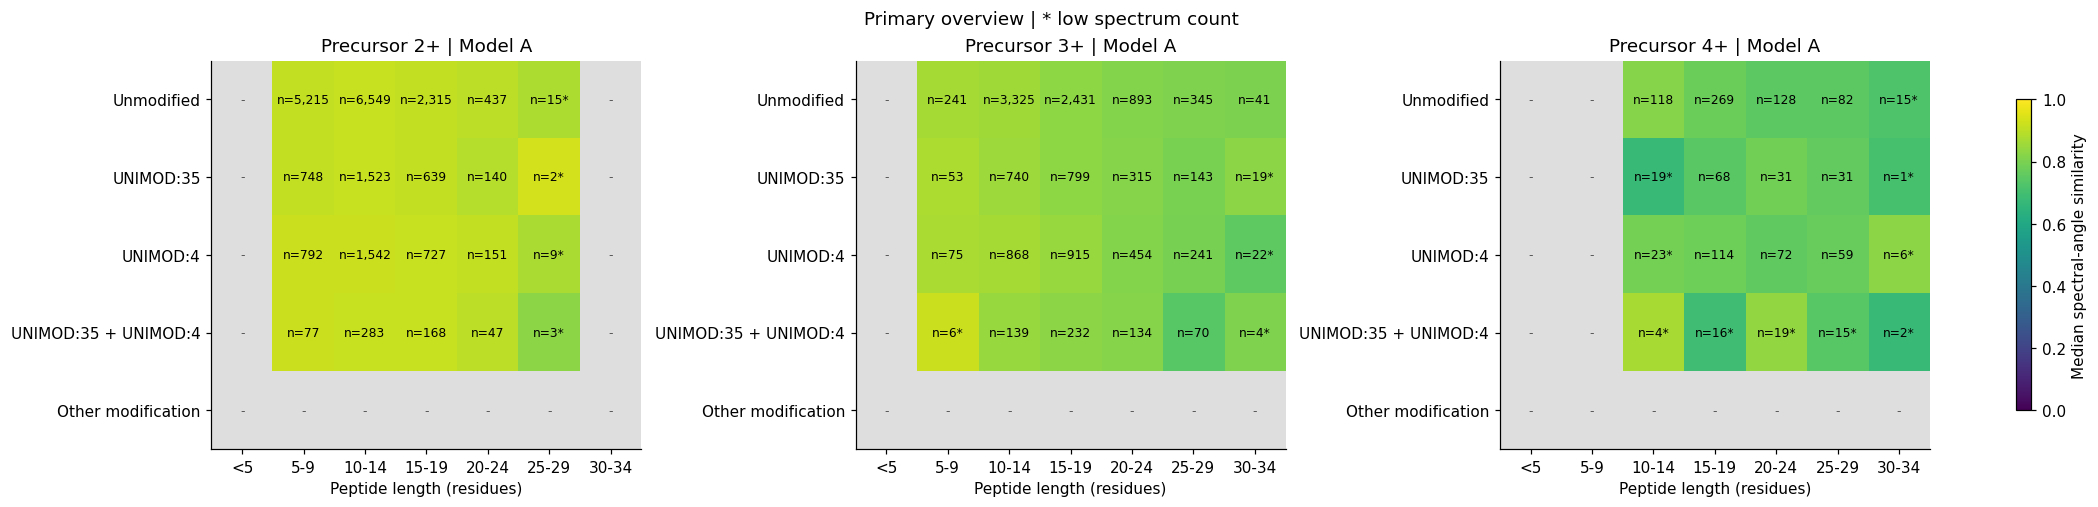

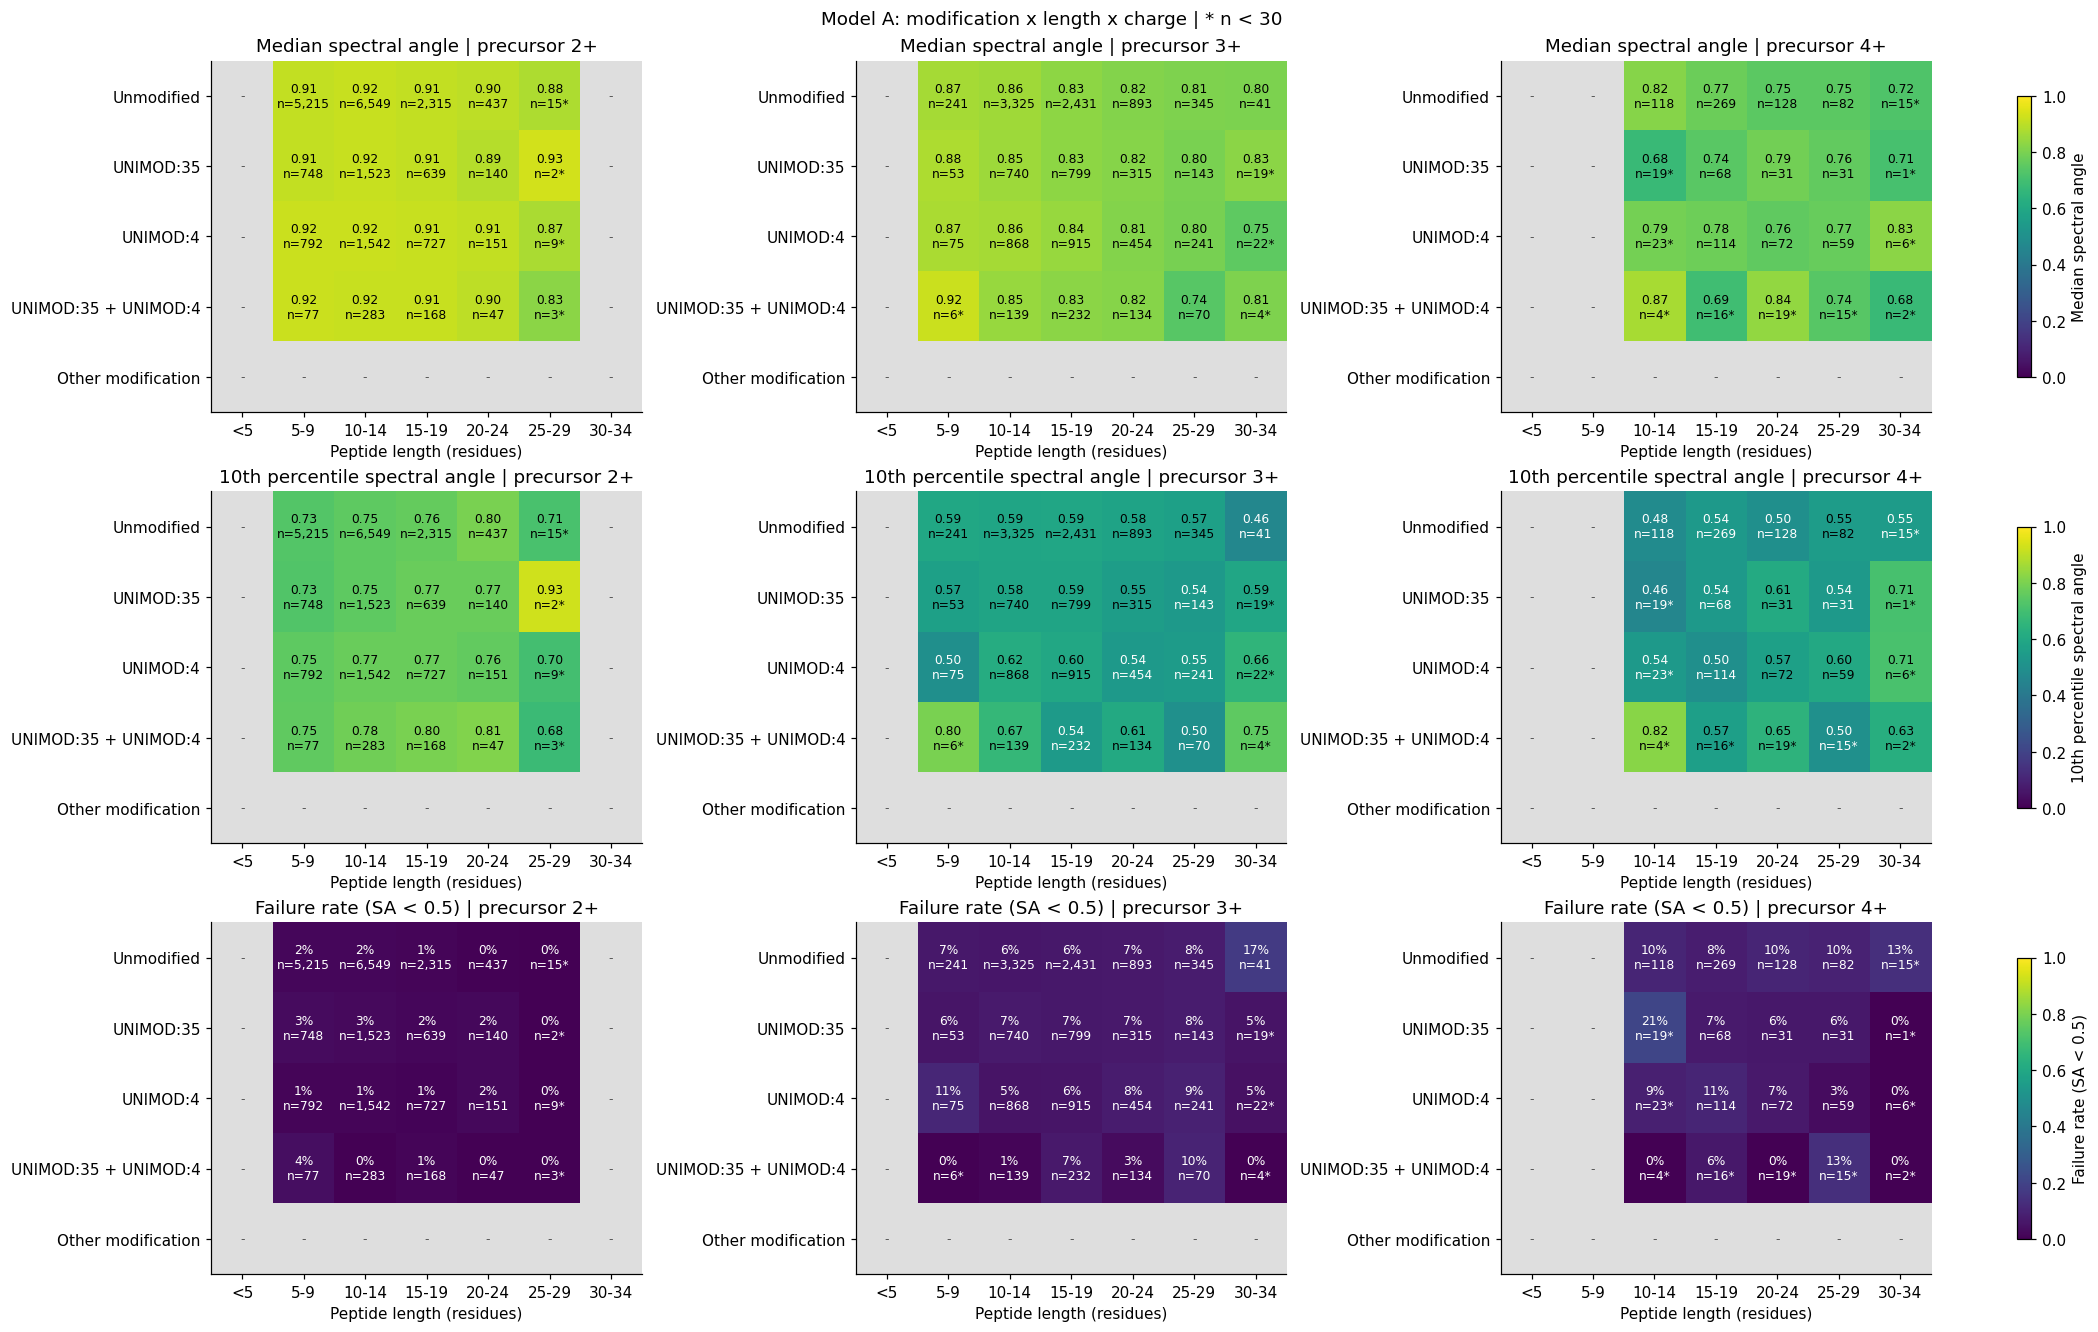

,model,precursor_charge,mod_class,length_bucket,median_sa,n,p10_sa,failure_rate,median_mae,n_peptides,low_support
0,Model A,2,UNIMOD:35,5-9,0.909,748,0.729,0.029,0.035,663,False
1,Model A,2,UNIMOD:35,10-14,0.917,1523,0.752,0.027,0.029,1346,False
2,Model A,2,UNIMOD:35,15-19,0.907,639,0.771,0.019,0.025,548,False
3,Model A,2,UNIMOD:35,20-24,0.887,140,0.773,0.021,0.027,113,False
4,Model A,2,UNIMOD:35,25-29,0.930,2,0.927,0.000,0.012,2,True
...,...,...,...,...,...,...,...,...,...,...,...
59,Model A,4,Unmodified,10-14,0.818,118,0.482,0.102,0.045,118,False
60,Model A,4,Unmodified,15-19,0.774,269,0.537,0.082,0.040,269,False
61,Model A,4,Unmodified,20-24,0.746,128,0.499,0.102,0.041,128,False
62,Model A,4,Unmodified,25-29,0.748,82,0.553,0.098,0.038,82,False


In [7]:
heatmap_cmap = plt.colormaps['viridis'].copy()
heatmap_cmap.set_bad('#dedede')

def heatmap_panel(axis, groups, statistic, annotation='full'):
    values = groups.pivot(index='mod_class', columns='length_bucket', values=statistic).reindex(
        index=MOD_CLASSES, columns=LENGTH_LABELS)
    counts = groups.pivot(index='mod_class', columns='length_bucket', values='n').reindex(
        index=MOD_CLASSES, columns=LENGTH_LABELS)
    image = axis.imshow(np.ma.masked_invalid(values.to_numpy(dtype=float)),
                        vmin=0, vmax=1, cmap=heatmap_cmap, aspect='auto')
    axis.set_xticks(range(len(LENGTH_LABELS)), LENGTH_LABELS)
    axis.set_yticks(range(len(MOD_CLASSES)), MOD_CLASSES)
    axis.set_xlabel('Peptide length (residues)')
    for row_index in range(len(MOD_CLASSES)):
        for column_index in range(len(LENGTH_LABELS)):
            value = values.iloc[row_index, column_index]
            count = counts.iloc[row_index, column_index]
            if pd.isna(value):
                text, color = '-', '#555555'
            else:
                marker = '*' if count < MIN_GROUP_N else ''
                if annotation == 'count':
                    text = f'n={int(count):,}{marker}'
                else:
                    label = f'{value:.0%}' if statistic == 'failure_rate' else f'{value:.2f}'
                    text = f'{label}\nn={int(count):,}{marker}'
                color = 'white' if value < 0.55 else 'black'
            axis.text(column_index, row_index, text, ha='center', va='center', fontsize=8, color=color)
    return image

primary_cube = cube[cube['model'].eq(PRIMARY_MODEL)]
figure, axes = plt.subplots(1, 3, figsize=(19, 4.5), constrained_layout=True)
for axis, charge in zip(axes, CHARGES):
    image = heatmap_panel(axis, primary_cube[primary_cube['precursor_charge'].eq(charge)], 'median_sa', 'count')
    axis.set_title(f'Precursor {charge}+ | {PRIMARY_MODEL}')
figure.colorbar(image, ax=axes, label='Median spectral-angle similarity', shrink=0.8)
figure.suptitle('Primary overview | * low spectrum count')
plt.show()

for model_name in PREDICTIONS:
    groups = cube[cube['model'].eq(model_name)]
    figure, axes = plt.subplots(3, 3, figsize=(19, 12), constrained_layout=True)
    for row_index, (statistic, label) in enumerate([
        ('median_sa', 'Median spectral angle'), ('p10_sa', '10th percentile spectral angle'),
        ('failure_rate', f'Failure rate (SA < {FAILURE_THRESHOLD:g})')
    ]):
        for column_index, charge in enumerate(CHARGES):
            image = heatmap_panel(axes[row_index, column_index], groups[groups['precursor_charge'].eq(charge)], statistic)
            axes[row_index, column_index].set_title(f'{label} | precursor {charge}+')
        figure.colorbar(image, ax=axes[row_index, :], label=label, shrink=0.8)
    figure.suptitle(f'{model_name}: modification x length x charge | * n < {MIN_GROUP_N}')
    plt.show()
display(cube.sort_values(GROUP_KEYS).round(3))

## Subgroup distributions and paired model comparison

.

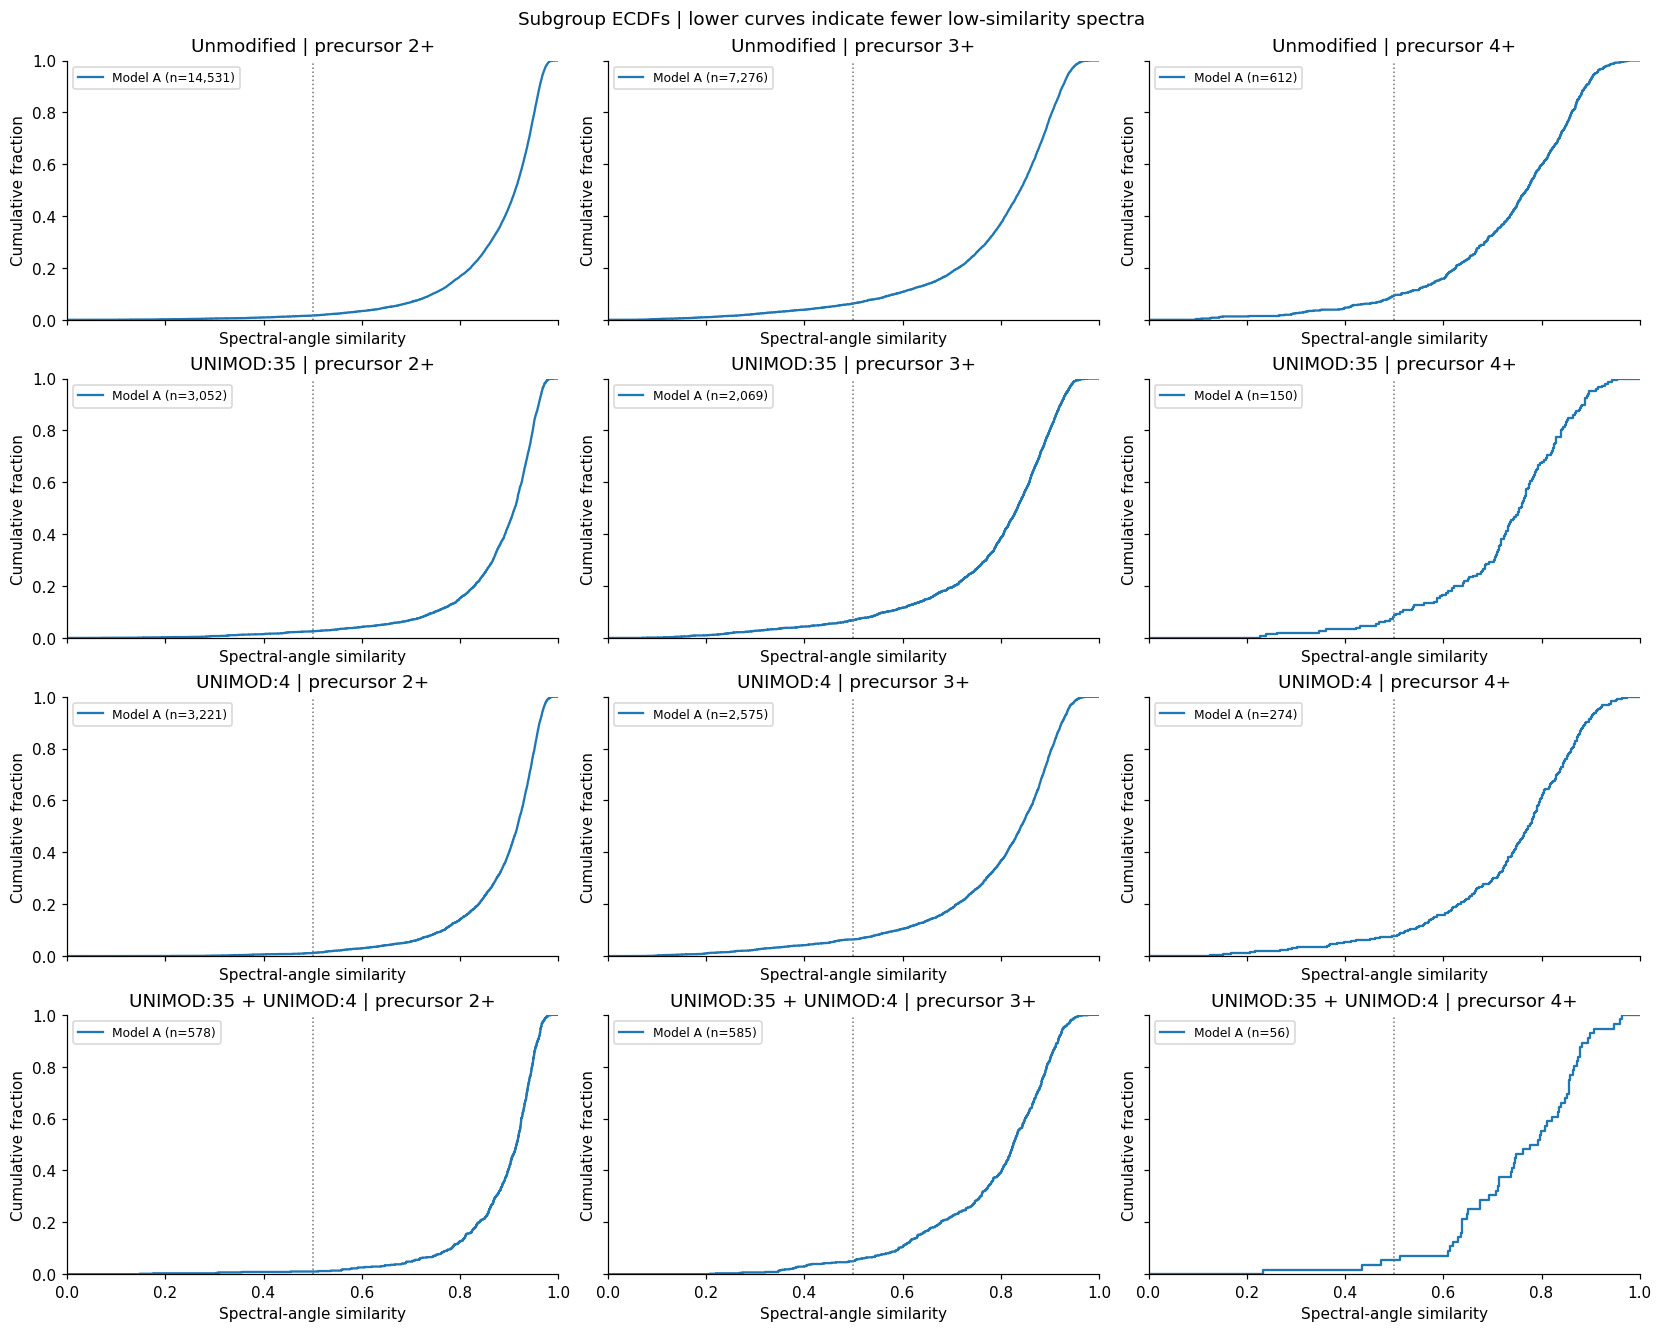

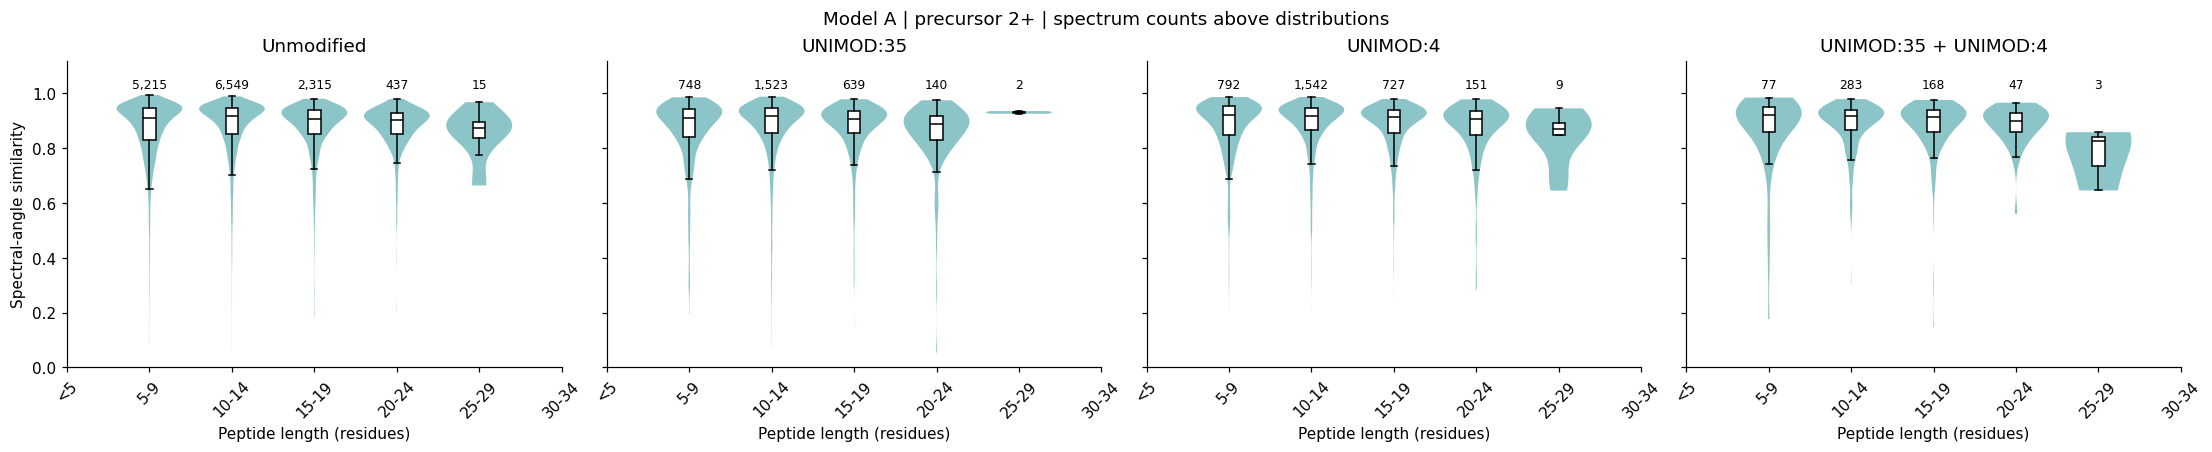

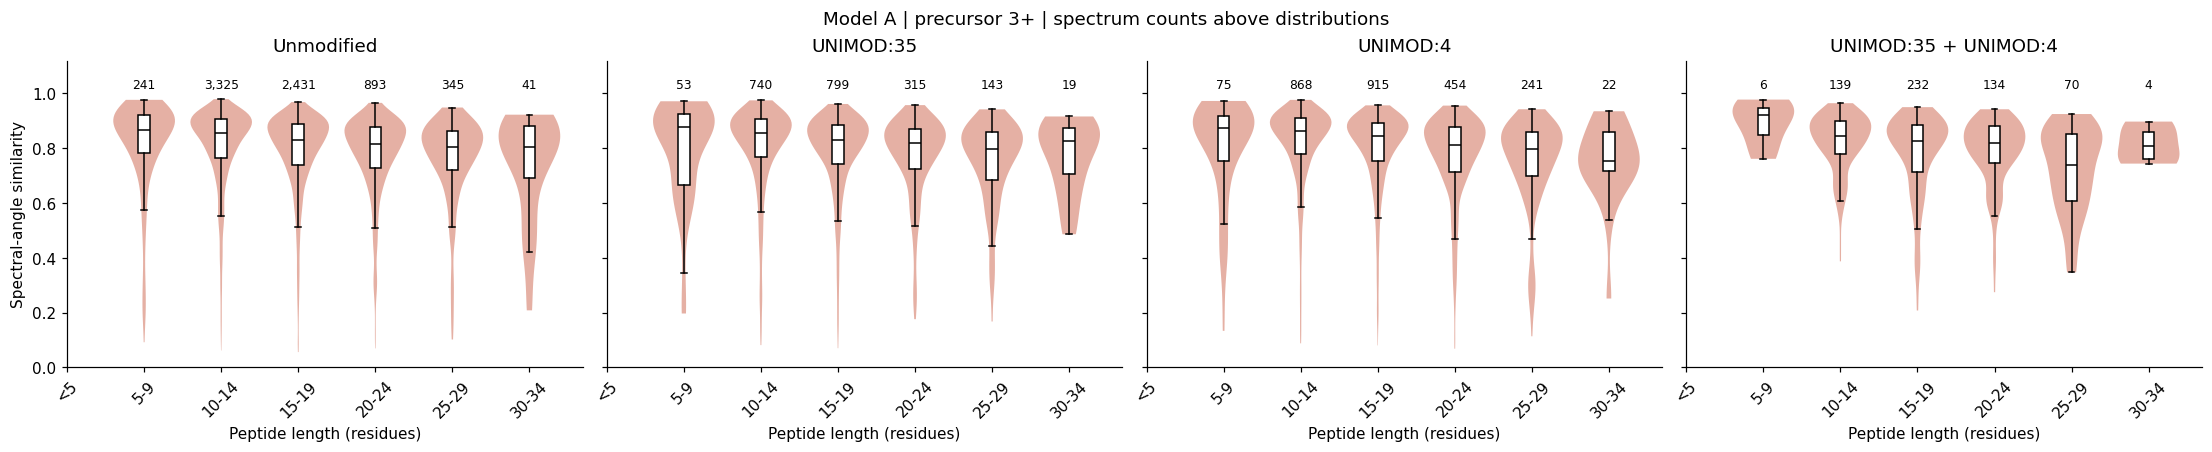

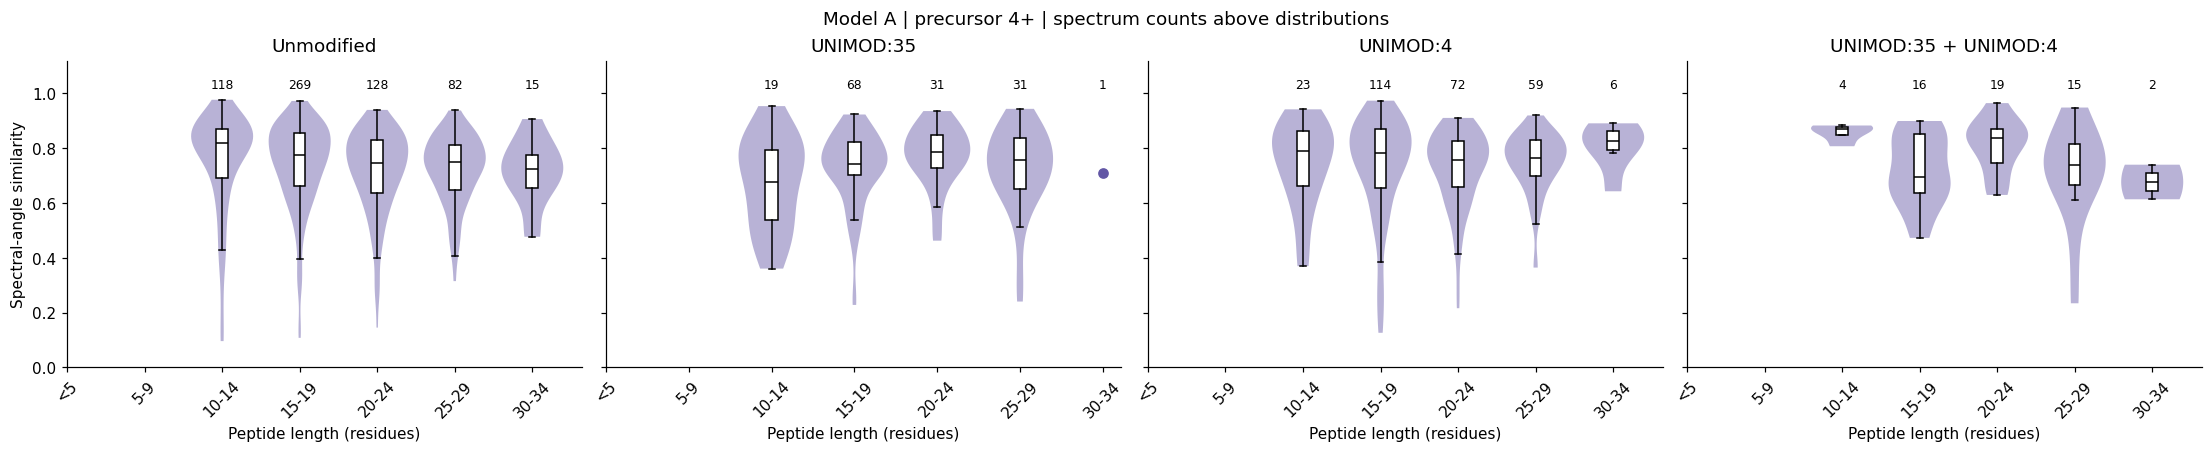

In [8]:
active_mod_classes = [category for category in MOD_CLASSES if category in set(spectra['mod_class'])]
model_colors = {name: plt.colormaps['tab10'](index % 10) for index, name in enumerate(PREDICTIONS)}
figure, axes = plt.subplots(len(active_mod_classes), 3, figsize=(15, 3 * len(active_mod_classes)),
                            sharex=True, sharey=True, squeeze=False, constrained_layout=True)
for row_index, category in enumerate(active_mod_classes):
    for column_index, charge in enumerate(CHARGES):
        axis = axes[row_index, column_index]
        group = metrics[metrics['mod_class'].eq(category) & metrics['precursor_charge'].eq(charge)]
        for model_name, frame in group.groupby('model', sort=False):
            values = np.sort(frame['spectral_angle'].to_numpy())
            axis.step(np.r_[0, values, 1], np.r_[0, np.arange(1, len(values) + 1) / len(values), 1],
                      where='post', label=f'{model_name} (n={len(values):,})', color=model_colors[model_name])
        axis.axvline(FAILURE_THRESHOLD, color='#777777', linestyle=':', linewidth=1)
        axis.set(xlim=(0, 1), ylim=(0, 1), title=f'{category} | precursor {charge}+',
                 xlabel='Spectral-angle similarity', ylabel='Cumulative fraction')
        if not group.empty:
            axis.legend(fontsize=8)
figure.suptitle('Subgroup ECDFs | lower curves indicate fewer low-similarity spectra')
plt.show()

primary_metrics = metrics[metrics['model'].eq(PRIMARY_MODEL)].copy()
for charge in CHARGES:
    figure, axes = plt.subplots(1, len(active_mod_classes), figsize=(5 * len(active_mod_classes), 4),
                                sharey=True, squeeze=False, constrained_layout=True)
    for axis, category in zip(axes[0], active_mod_classes):
        frame = primary_metrics[primary_metrics['precursor_charge'].eq(charge) & primary_metrics['mod_class'].eq(category)]
        for position, bucket in enumerate(LENGTH_LABELS):
            values = frame.loc[frame['length_bucket'].eq(bucket), 'spectral_angle'].to_numpy()
            if len(values) == 0:
                continue
            if len(values) > 1 and np.ptp(values) > 0:
                violin = axis.violinplot([values], positions=[position], widths=0.8, showextrema=False)
                for body in violin['bodies']:
                    body.set_facecolor(COLORS[charge])
                    body.set_alpha(0.45)
                axis.boxplot([values], positions=[position], widths=0.15, showfliers=False,
                             manage_ticks=False, medianprops={'color': 'black'}, patch_artist=True,
                             boxprops={'facecolor': 'white'})
            else:
                axis.plot(position, values[0], 'o', color=COLORS[charge])
            axis.text(position, 1.02, f'{len(values):,}', ha='center', fontsize=8)
        axis.set_xticks(range(len(LENGTH_LABELS)), LENGTH_LABELS, rotation=45)
        axis.set(ylim=(0, 1.12), xlabel='Peptide length (residues)', title=category)
    axes[0, 0].set_ylabel('Spectral-angle similarity')
    figure.suptitle(f'{PRIMARY_MODEL} | precursor {charge}+ | spectrum counts above distributions')
    plt.show()

if len(PREDICTIONS) > 1:
    paired = metrics.pivot(index='spectrum_id', columns='model', values='spectral_angle')
    comparisons = []
    for other in PREDICTIONS:
        if other == PRIMARY_MODEL:
            continue
        for category in active_mod_classes + ['All modified']:
            selected = spectra['modified'].eq('Modified') if category == 'All modified' else spectra['mod_class'].eq(category)
            ids = spectra.loc[selected, 'spectrum_id']
            reference, alternative = paired.loc[ids, PRIMARY_MODEL], paired.loc[ids, other]
            difference = alternative - reference
            comparisons.append({'category': category, 'comparison': f'{other} vs {PRIMARY_MODEL}',
                                'n': len(ids), 'median_paired_change': difference.median(),
                                'fraction_better': (difference > 1e-8).mean(),
                                'fraction_tied': np.isclose(difference, 0, atol=1e-8, rtol=0).mean(),
                                'reference_failure_rate': (reference < FAILURE_THRESHOLD).mean(),
                                'alternative_failure_rate': (alternative < FAILURE_THRESHOLD).mean()})
    display(pd.DataFrame(comparisons).round(4))

## Exact peptide length with cluster-bootstrap intervals
.

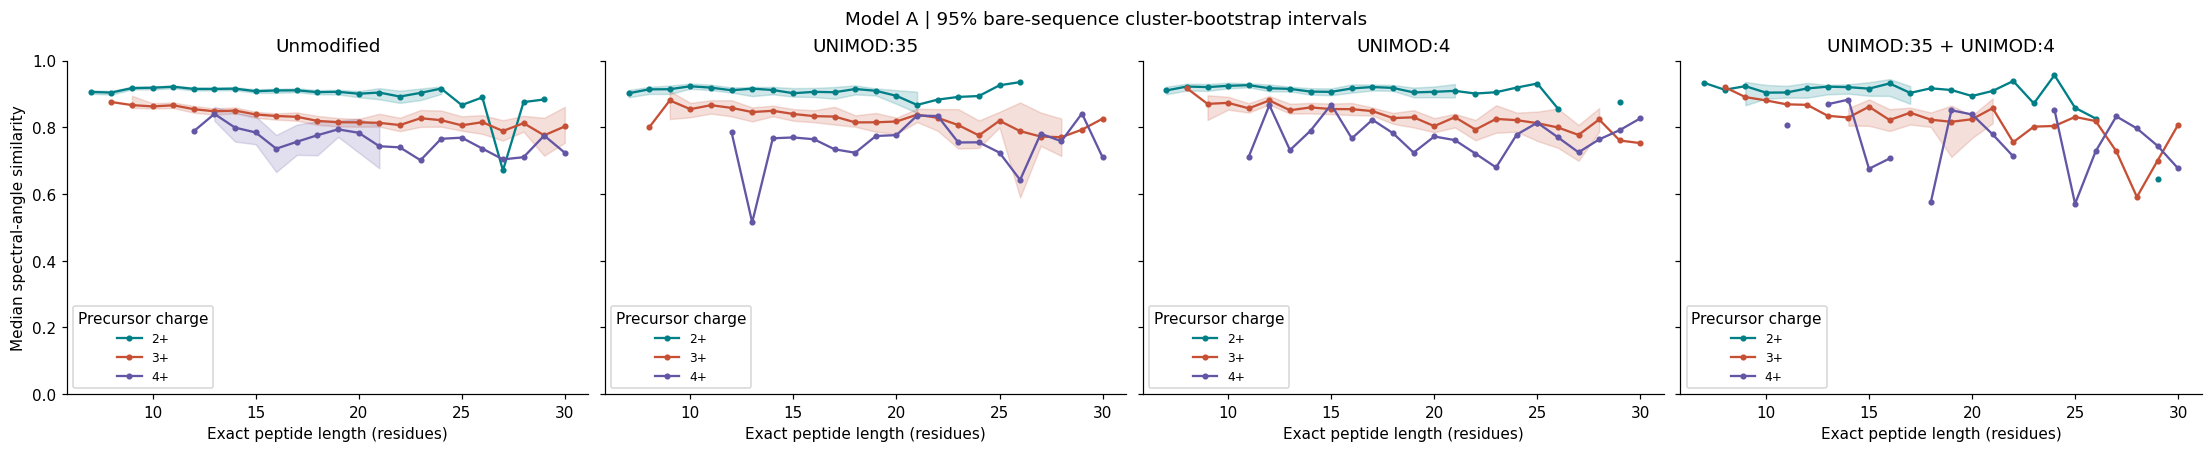

,model,mod_class,precursor_charge,peptide_length,median_sa,ci_low,ci_high,n,n_peptides
0,Model A,UNIMOD:35,2,7,0.902,0.890,0.911,160,152
1,Model A,UNIMOD:35,2,8,0.914,0.900,0.921,262,230
2,Model A,UNIMOD:35,2,9,0.914,0.900,0.925,326,281
3,Model A,UNIMOD:35,2,10,0.923,0.915,0.931,342,308
4,Model A,UNIMOD:35,2,11,0.919,0.911,0.928,368,325
...,...,...,...,...,...,...,...,...,...
247,Model A,Unmodified,4,26,0.736,NaN,NaN,21,21
248,Model A,Unmodified,4,27,0.704,NaN,NaN,20,20
249,Model A,Unmodified,4,28,0.710,NaN,NaN,13,13
250,Model A,Unmodified,4,29,0.775,NaN,NaN,10,10


In [9]:
def cluster_median_interval(frame, generator):
    values = frame['spectral_angle'].to_numpy()
    clusters = [group['spectral_angle'].to_numpy() for _, group in frame.groupby('bare_sequence', sort=True)]
    if len(values) < MIN_GROUP_N or len(clusters) < 2:
        return float(np.median(values)), np.nan, np.nan, len(clusters)
    medians = np.empty(BOOTSTRAP_REPLICATES)
    for replicate in range(BOOTSTRAP_REPLICATES):
        selected = generator.integers(0, len(clusters), size=len(clusters))
        medians[replicate] = np.median(np.concatenate([clusters[index] for index in selected]))
    lower, upper = np.quantile(medians, [0.025, 0.975])
    return float(np.median(values)), float(lower), float(upper), len(clusters)

bootstrap_rng = np.random.default_rng(SEED)
length_rows = []
for (model_name, category, charge, length), frame in metrics.groupby(
    ['model', 'mod_class', 'precursor_charge', 'peptide_length'], observed=True, sort=True
):
    median, lower, upper, n_peptides = cluster_median_interval(frame, bootstrap_rng)
    length_rows.append({'model': model_name, 'mod_class': category, 'precursor_charge': charge,
                        'peptide_length': length, 'median_sa': median, 'ci_low': lower, 'ci_high': upper,
                        'n': len(frame), 'n_peptides': n_peptides})
length_summary = pd.DataFrame(length_rows)
for model_name in PREDICTIONS:
    figure, axes = plt.subplots(1, len(active_mod_classes), figsize=(5 * len(active_mod_classes), 4),
                                sharey=True, squeeze=False, constrained_layout=True)
    for axis, category in zip(axes[0], active_mod_classes):
        for charge in CHARGES:
            frame = length_summary[length_summary['model'].eq(model_name) & length_summary['mod_class'].eq(category)
                                   & length_summary['precursor_charge'].eq(charge)]
            if frame.empty:
                continue
            frame = frame.set_index('peptide_length').reindex(range(2, max_length + 1))
            positions = frame.index.to_numpy(dtype=float)
            axis.plot(positions, frame['median_sa'].to_numpy(dtype=float), marker='.',
                      color=COLORS[charge], label=f'{charge}+')
            axis.fill_between(positions, frame['ci_low'].to_numpy(dtype=float), frame['ci_high'].to_numpy(dtype=float),
                              color=COLORS[charge], alpha=0.18)
        axis.set(title=category, xlabel='Exact peptide length (residues)', ylim=(0, 1))
        axis.legend(title='Precursor charge', fontsize=8)
    axes[0, 0].set_ylabel('Median spectral-angle similarity')
    figure.suptitle(f'{model_name} | 95% bare-sequence cluster-bootstrap intervals')
    plt.show()
display(length_summary.round(3))

## Fragment-level errors and intensity hexbin facets
.

880,696 valid fragment slots for Model A; fragment charge fixed at 1+


n_fragments  n_spectra  \
ion_series precursor_charge modified                             
b          2                Modified          79239       6851   
                            Unmodified       151871      14531   
           3                Modified          83265       5229   
                            Unmodified       105746       7276   
           4                Modified           9275        480   
                            Unmodified        10952        612   
y          2                Modified          79239       6851   
                            Unmodified       151871      14531   
           3                Modified          83265       5229   
                            Unmodified       105746       7276   
           4                Modified           9275        480   
                            Unmodified        10952        612   

                                        annotated_fraction  mean_abs_error  \
ion_series precursor_charge modified                                         
b          2                Modified                 0.861           0.034   
                            Unmodified               0.865           0.036   
           3                Modified                 0.672           0.046   
                            Unmodified               0.697           0.045   
           4                Modified                 0.519           0.046   
                            Unmodified               0.541           0.049   
y          2                Modified                 0.876           0.042   
                            Unmodified               0.904           0.043   
           3                Modified                 0.656           0.048   
                            Unmodified               0.685           0.047   
           4                Modified                 0.508           0.045   
                            Unmodified               0.526           0.046   

                                        median_abs_error  signed_bias  
ion_series precursor_charge modified                                   
b          2                Modified               0.012       -0.000  
                            Unmodified             0.012        0.003  
           3                Modified               0.008        0.012  
                            Unmodified             0.009        0.013  
           4                Modified               0.002        0.008  
                            Unmodified             0.003        0.010  
y          2                Modified               0.013        0.005  
                            Unmodified             0.014        0.008  
           3                Modified               0.007        0.016  
                            Unmodified             0.008        0.015  
           4                Modified               0.002        0.006  
                            Unmodified             0.002        0.010

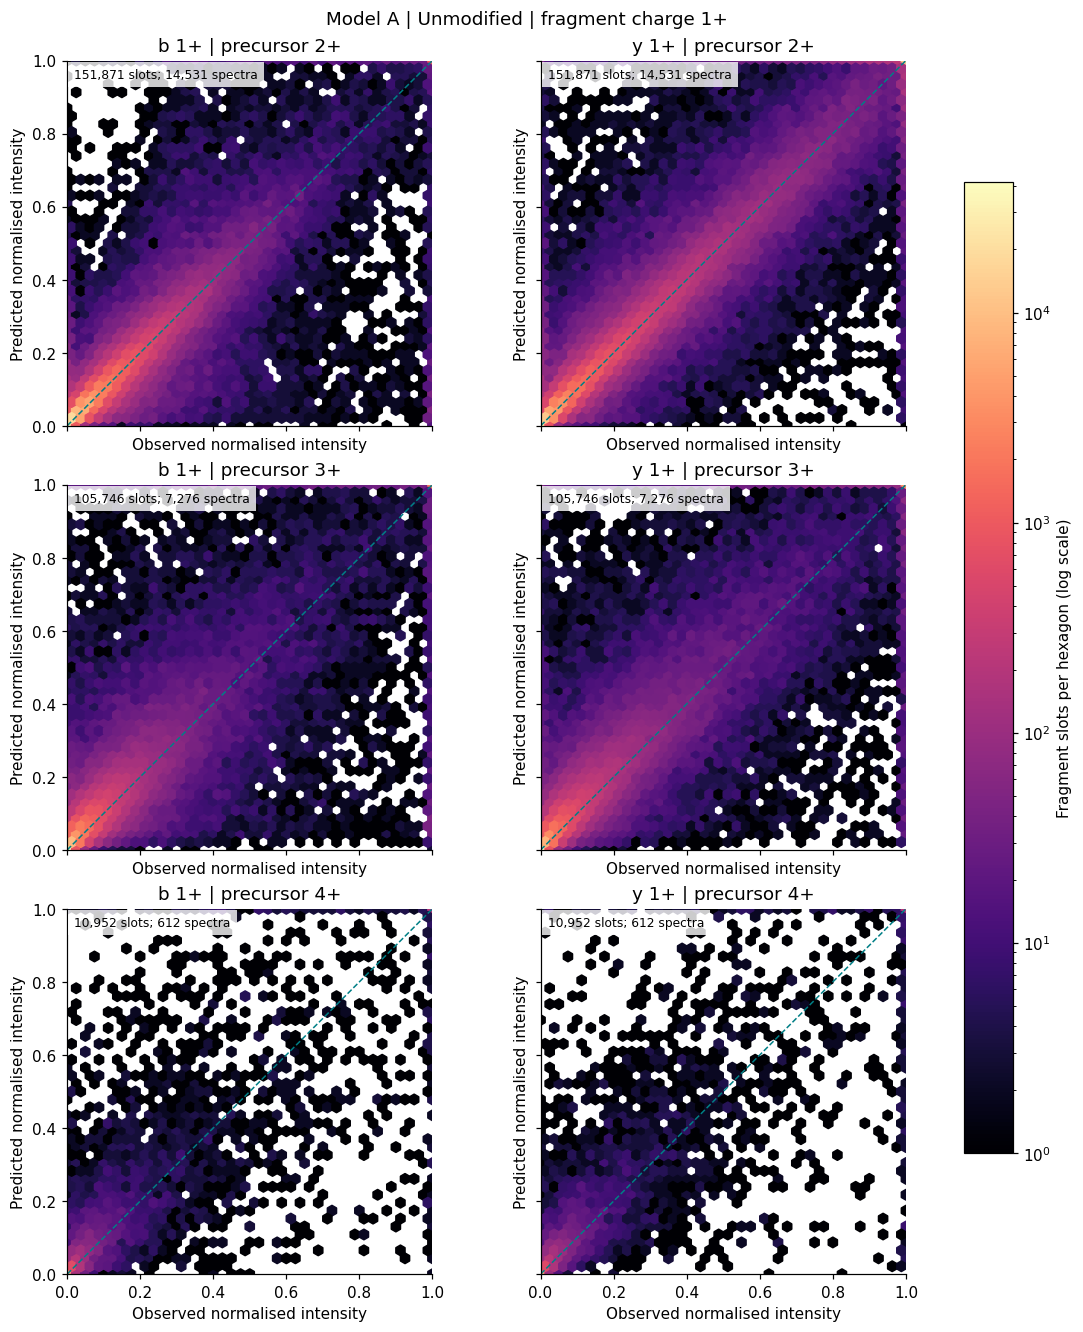

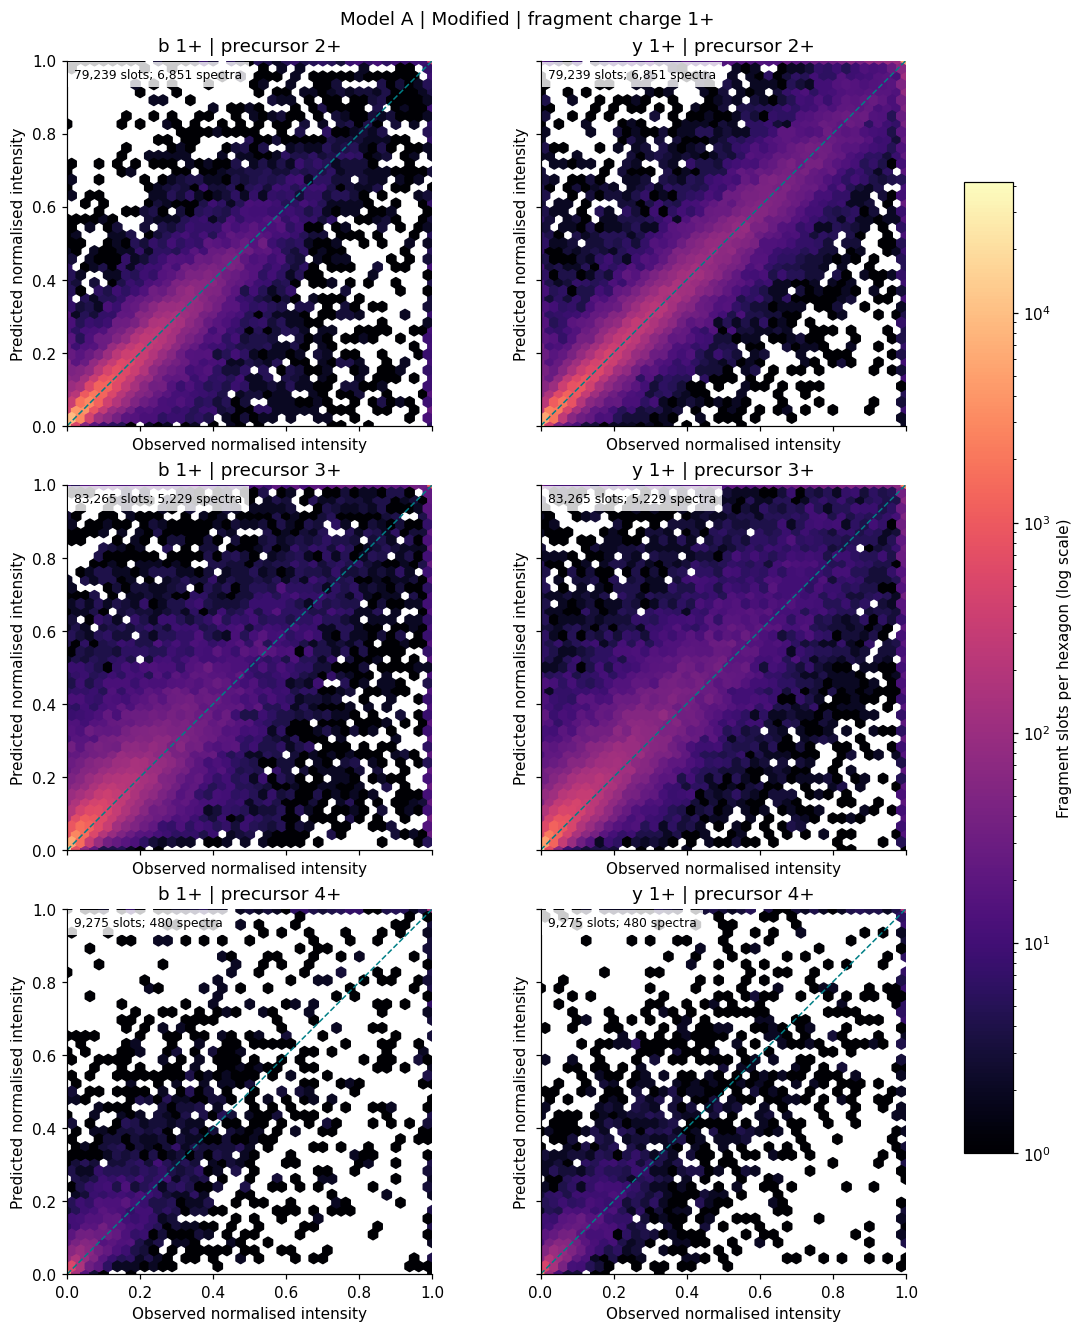

In [10]:
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable

spectrum_rows, slots = np.nonzero(MASK)
fragment_columns = ['spectrum_id', 'precursor_charge', 'peptide_length', 'mod_class', 'modified', 'frag']
fragments = spectra.iloc[spectrum_rows][fragment_columns].reset_index(drop=True).copy()
fragments['slot'] = slots
fragments['ion_series'] = np.asarray(c.ION_TYPES)[slots % c.N_ION_TYPES]
fragments['fragment_number'] = slots // c.N_ION_TYPES + 1
fragments['fragment_charge'] = 1
fragments['cleavage_position'] = np.where(fragments['ion_series'].eq('b'), fragments['fragment_number'],
                                         fragments['peptide_length'] - fragments['fragment_number'])
fragments['relative_cleavage'] = fragments['cleavage_position'] / fragments['peptide_length']
fragments['observed'] = OBSERVED_NORMALIZED[spectrum_rows, slots]
fragments['predicted'] = PREDICTED_NORMALIZED[PRIMARY_MODEL][spectrum_rows, slots]
fragments['signed_error'] = fragments['predicted'] - fragments['observed']
fragments['absolute_error'] = fragments['signed_error'].abs()
fragments['relative_absolute_error'] = np.divide(
    fragments['absolute_error'].to_numpy(), fragments['observed'].to_numpy(),
    out=np.full(len(fragments), np.nan), where=fragments['observed'].to_numpy() > 0
)
annotation_mask = np.zeros_like(MASK)
for row_index, row in enumerate(spectra.itertuples()):
    for ion in row.matched_ions:
        number = int(ion[1:])
        if 1 <= number < row.peptide_length:
            annotation_mask[row_index, c.fragment_slot(ion[0], number)] = True
fragments['annotated'] = annotation_mask[spectrum_rows, slots]
assert fragments['cleavage_position'].ge(1).all()
assert (fragments['cleavage_position'] < fragments['peptide_length']).all()
print(f'{len(fragments):,} valid fragment slots for {PRIMARY_MODEL}; fragment charge fixed at 1+')
display(fragments.groupby(['ion_series', 'precursor_charge', 'modified']).agg(
    n_fragments=('slot', 'size'), n_spectra=('spectrum_id', 'nunique'),
    annotated_fraction=('annotated', 'mean'), mean_abs_error=('absolute_error', 'mean'),
    median_abs_error=('absolute_error', 'median'), signed_bias=('signed_error', 'mean')
).round(3))

hexbin_figures = []
hexbin_collections = []
for modification_status in ('Unmodified', 'Modified'):
    figure, axes = plt.subplots(3, 2, figsize=(10, 12), sharex=True, sharey=True, constrained_layout=True)
    for row_index, charge in enumerate(CHARGES):
        for column_index, ion_series in enumerate(c.ION_TYPES):
            axis = axes[row_index, column_index]
            frame = fragments[fragments['modified'].eq(modification_status) & fragments['precursor_charge'].eq(charge)
                              & fragments['ion_series'].eq(ion_series)]
            if frame.empty:
                axis.text(0.5, 0.5, 'No spectra', ha='center')
            else:
                collection = axis.hexbin(frame['observed'], frame['predicted'], gridsize=40, extent=(0, 1, 0, 1),
                                         mincnt=1, norm=LogNorm(vmin=1), cmap='magma')
                hexbin_collections.append(collection)
            axis.plot([0, 1], [0, 1], color='#007f86', linestyle='--', linewidth=1)
            axis.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xlabel='Observed normalised intensity',
                     ylabel='Predicted normalised intensity', title=f'{ion_series} 1+ | precursor {charge}+')
            axis.text(0.02, 0.98, f'{len(frame):,} slots; {frame.spectrum_id.nunique():,} spectra',
                      transform=axis.transAxes, va='top', fontsize=8,
                      bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
    figure.suptitle(f'{PRIMARY_MODEL} | {modification_status} | fragment charge 1+')
    hexbin_figures.append((figure, axes))
if hexbin_collections:
    maximum_count = max(2, max(float(collection.get_array().max()) for collection in hexbin_collections))
    density_norm = LogNorm(vmin=1, vmax=maximum_count)
    for collection in hexbin_collections:
        collection.set_norm(density_norm)
    density_mappable = ScalarMappable(norm=density_norm, cmap='magma')
    for figure, axes in hexbin_figures:
        figure.colorbar(density_mappable, ax=axes, label='Fragment slots per hexagon (log scale)', shrink=0.8)
plt.show()

## Error by cleavage position



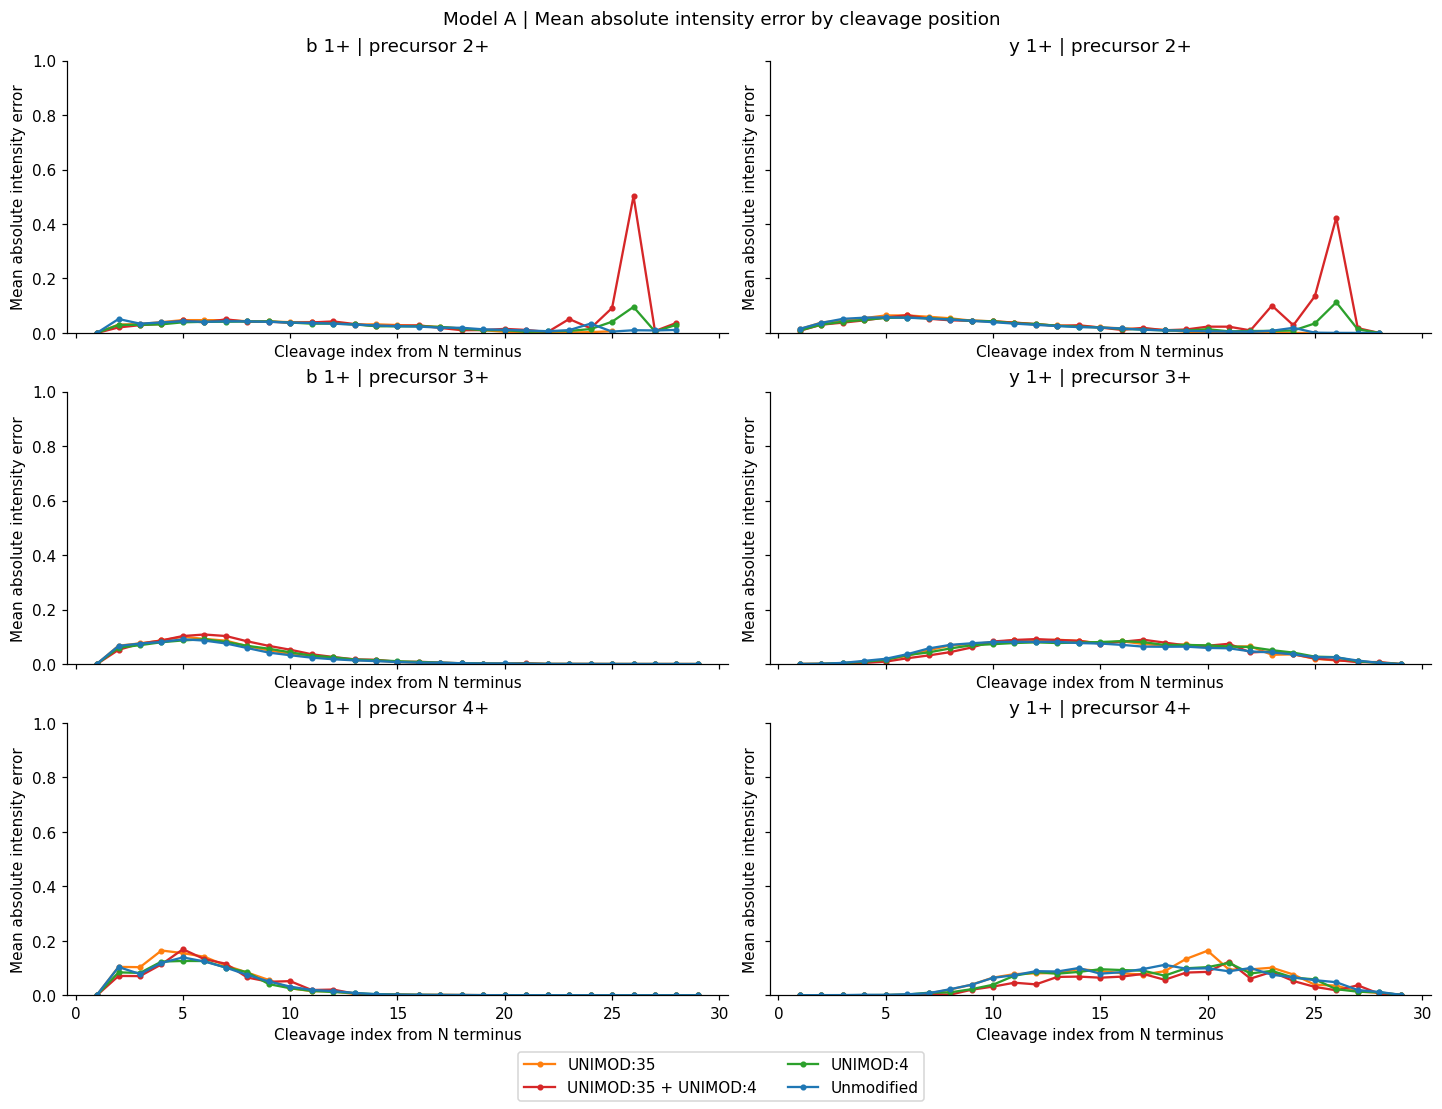

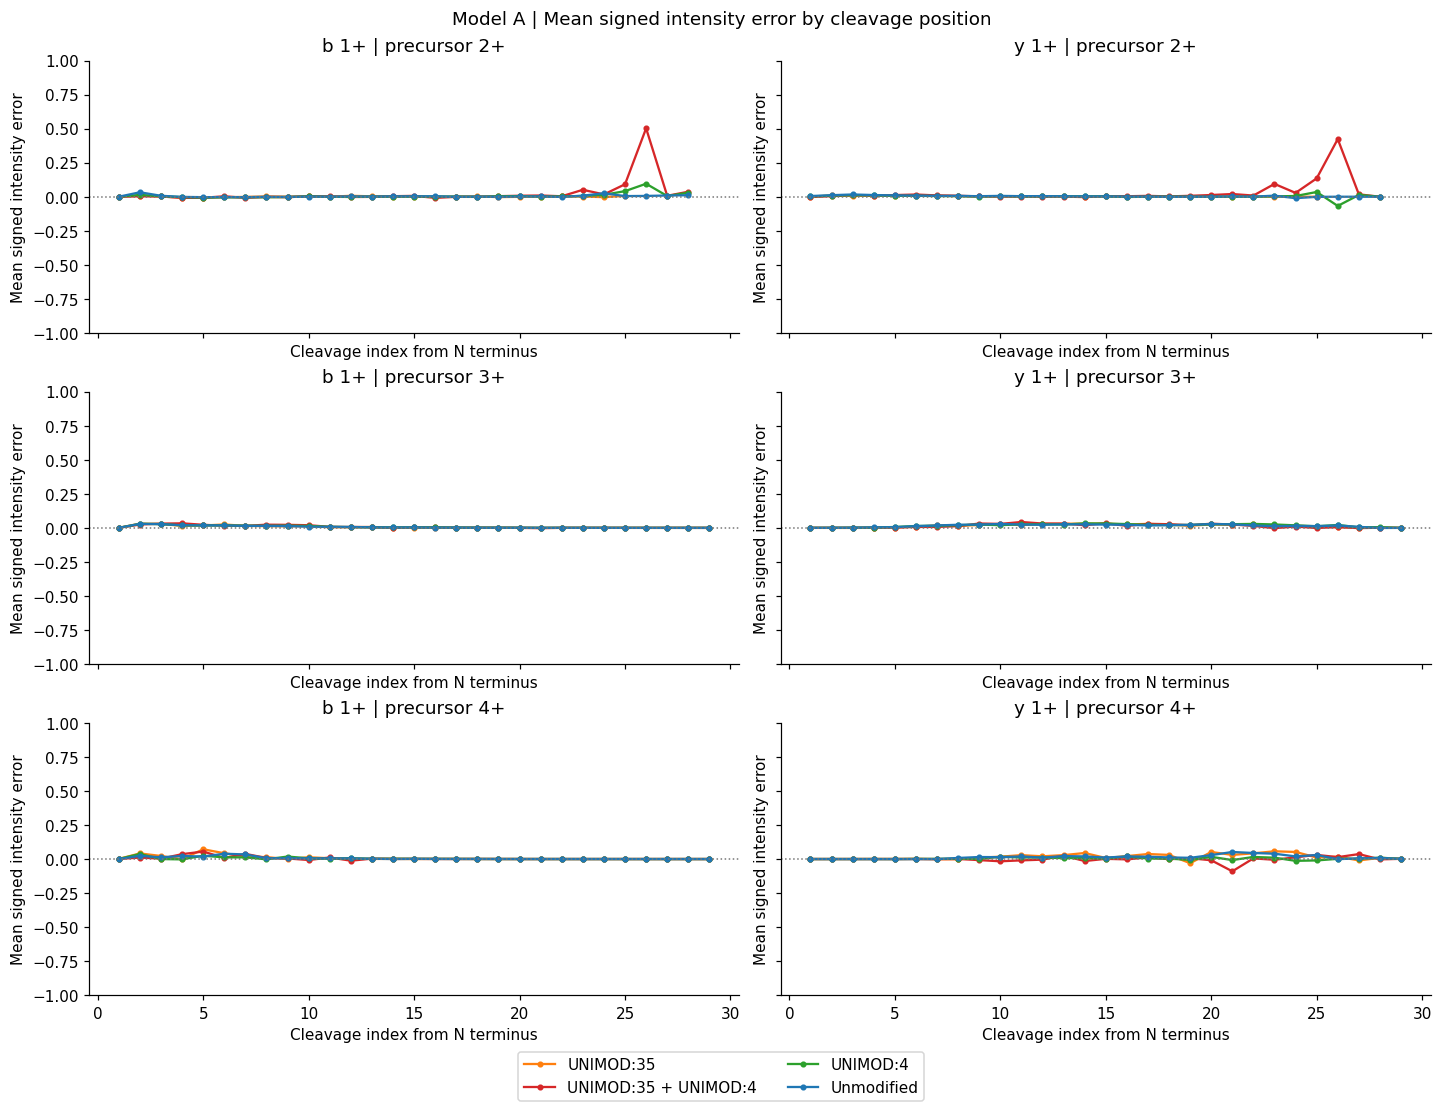

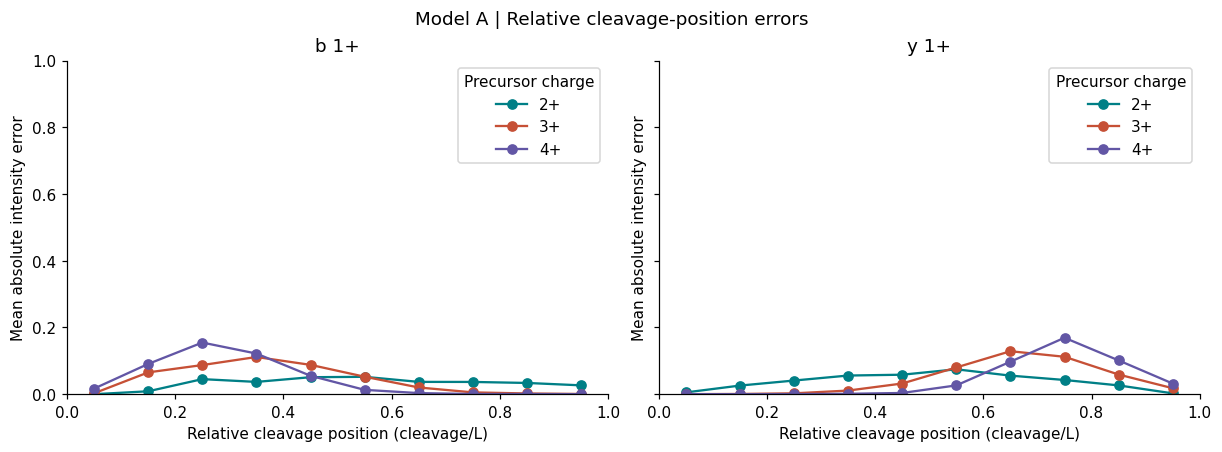

,precursor_charge,ion_series,mod_class,cleavage_position,mean_abs_error,median_abs_error,signed_bias,p90_abs_error,n_fragments,n_spectra
50,2,b,UNIMOD:35 + UNIMOD:4,26,0.502,0.502,0.502,0.502,1,1
159,2,y,UNIMOD:35 + UNIMOD:4,26,0.423,0.423,0.423,0.423,1,1
483,4,b,UNIMOD:35 + UNIMOD:4,5,0.169,0.073,0.055,0.502,56,56
453,4,b,UNIMOD:35,4,0.164,0.084,-0.001,0.457,150,150
585,4,y,UNIMOD:35,20,0.163,0.074,0.052,0.366,51,51
454,4,b,UNIMOD:35,5,0.155,0.080,0.072,0.407,150,150
455,4,b,UNIMOD:35,6,0.141,0.075,0.042,0.337,150,150
541,4,b,Unmodified,5,0.139,0.063,0.018,0.397,612,612
158,2,y,UNIMOD:35 + UNIMOD:4,25,0.135,0.135,0.135,0.242,2,2
584,4,y,UNIMOD:35,19,0.133,0.047,-0.031,0.322,63,63


In [11]:
mod_colors = {category: plt.colormaps['tab10'](index) for index, category in enumerate(MOD_CLASSES)}
cleavage_summary = fragments.groupby(['precursor_charge', 'ion_series', 'mod_class', 'cleavage_position']).agg(
    mean_abs_error=('absolute_error', 'mean'), median_abs_error=('absolute_error', 'median'),
    signed_bias=('signed_error', 'mean'), p90_abs_error=('absolute_error', lambda values: values.quantile(0.9)),
    n_fragments=('slot', 'size'), n_spectra=('spectrum_id', 'nunique')
).reset_index()
for statistic, label in [('mean_abs_error', 'Mean absolute intensity error'), ('signed_bias', 'Mean signed intensity error')]:
    figure, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey=True, constrained_layout=True)
    for row_index, charge in enumerate(CHARGES):
        for column_index, ion_series in enumerate(c.ION_TYPES):
            axis = axes[row_index, column_index]
            frame = cleavage_summary[cleavage_summary['precursor_charge'].eq(charge) & cleavage_summary['ion_series'].eq(ion_series)]
            for category, group in frame.groupby('mod_class', sort=False):
                group = group.set_index('cleavage_position').reindex(range(1, max_length))
                axis.plot(group.index, group[statistic], marker='.', label=category, color=mod_colors[category])
            if statistic == 'signed_bias':
                axis.axhline(0, color='#777777', linestyle=':', linewidth=1)
                axis.set_ylim(-1, 1)
            else:
                axis.set_ylim(0, 1)
            axis.set(title=f'{ion_series} 1+ | precursor {charge}+', xlabel='Cleavage index from N terminus', ylabel=label)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=2)
    figure.suptitle(f'{PRIMARY_MODEL} | {label} by cleavage position')
    plt.show()

fragments['relative_position_bin'] = np.minimum((fragments['relative_cleavage'] * 10).astype(int), 9)
relative_summary = fragments.groupby(['precursor_charge', 'ion_series', 'relative_position_bin']).agg(
    mean_abs_error=('absolute_error', 'mean'), n_spectra=('spectrum_id', 'nunique')
).reset_index()
figure, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for axis, ion_series in zip(axes, c.ION_TYPES):
    for charge in CHARGES:
        frame = relative_summary[relative_summary['ion_series'].eq(ion_series) & relative_summary['precursor_charge'].eq(charge)]
        axis.plot((frame['relative_position_bin'] + 0.5) / 10, frame['mean_abs_error'],
                  marker='o', color=COLORS[charge], label=f'{charge}+')
    axis.set(title=f'{ion_series} 1+', xlabel='Relative cleavage position (cleavage/L)',
             ylabel='Mean absolute intensity error', xlim=(0, 1), ylim=(0, 1))
    axis.legend(title='Precursor charge')
figure.suptitle(f'{PRIMARY_MODEL} | Relative cleavage-position errors')
plt.show()
display(cleavage_summary.sort_values('mean_abs_error', ascending=False).head(20).round(3))

## Error relative to modification position

.

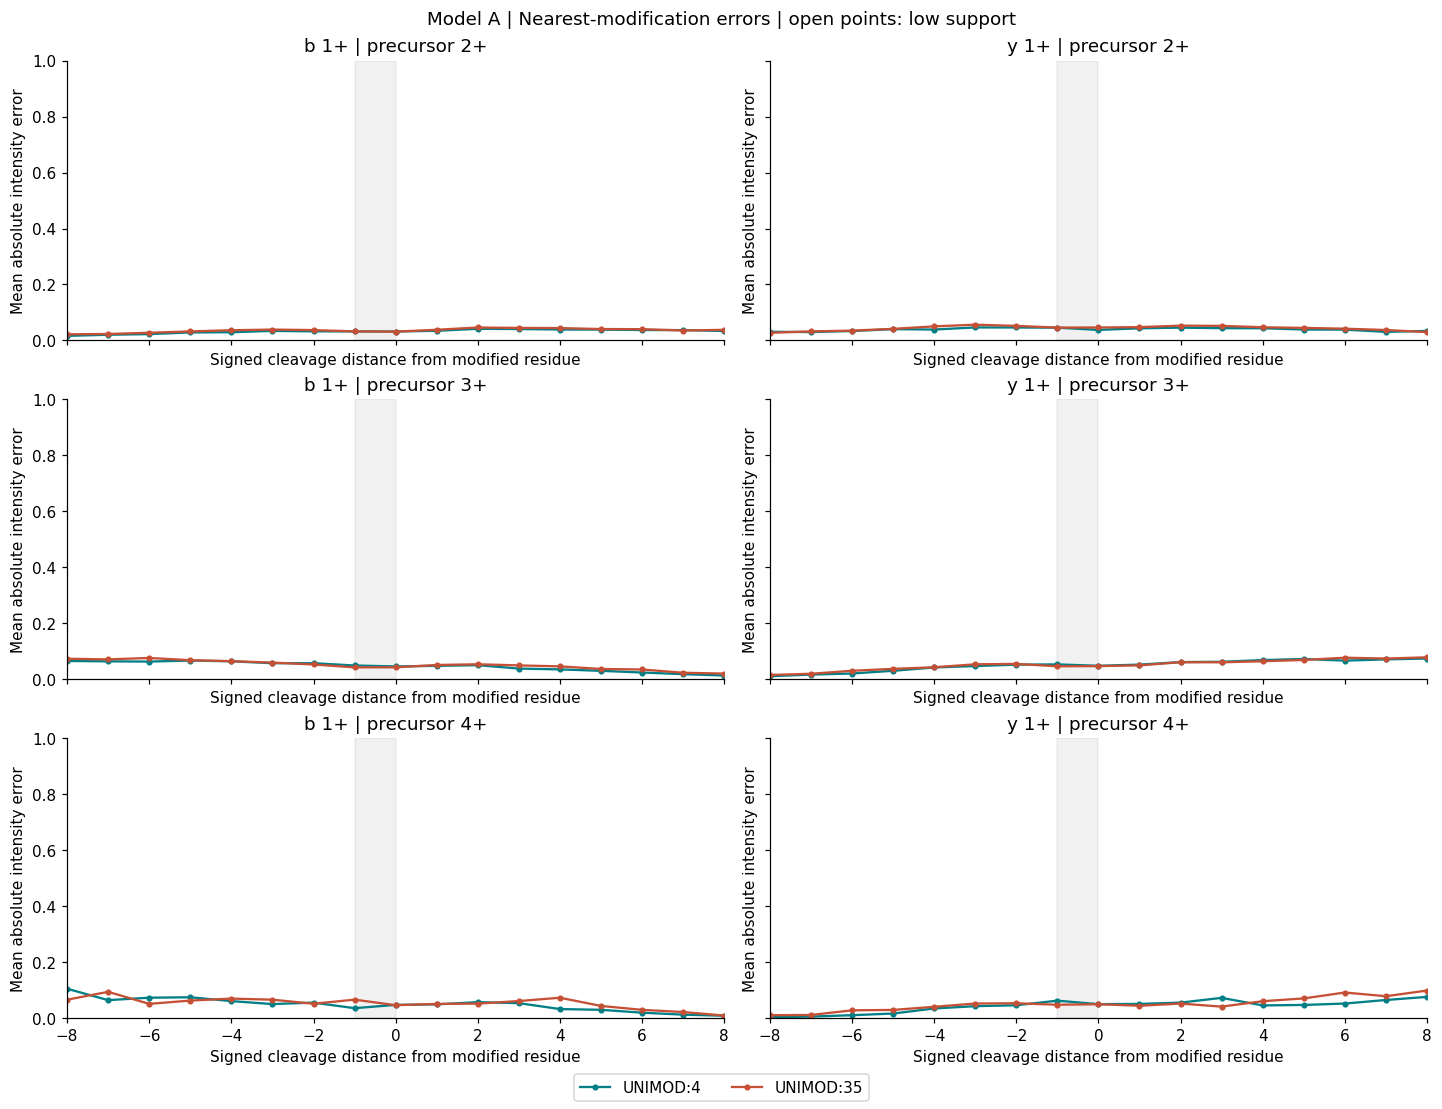

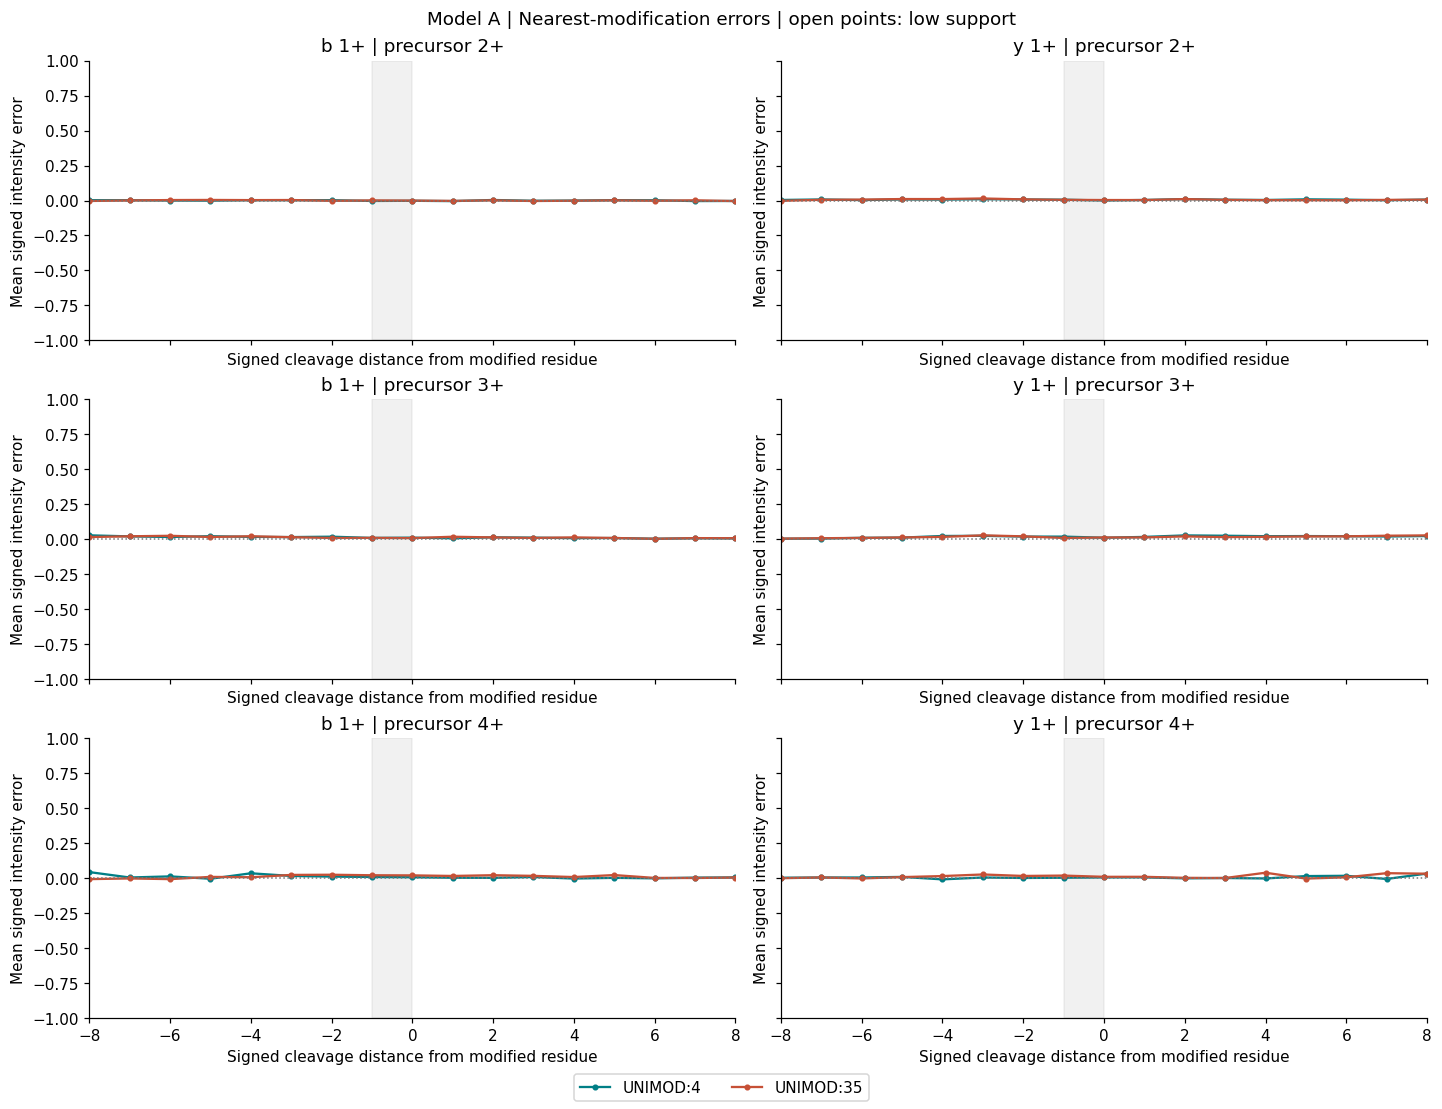

,precursor_charge,ion_series,unimod_code,distance_to_modification,mean_abs_error,signed_bias,median_abs_error,n_fragments,n_spectra
483,4,b,35,-25,0.184,-0.183,0.002,3,3
627,4,y,35,12,0.143,-0.009,0.064,48,48
494,4,b,35,-14,0.117,-0.014,0.031,41,41
628,4,y,35,13,0.115,0.030,0.031,43,43
583,4,y,4,20,0.112,-0.082,0.025,11,11
484,4,b,35,-24,0.108,-0.065,0.007,5,5
574,4,y,4,11,0.108,0.021,0.046,114,114
485,4,b,35,-23,0.108,0.001,0.016,6,6
448,4,b,4,-8,0.104,0.042,0.019,171,171
633,4,y,35,18,0.102,0.051,0.053,16,16


In [12]:
nearest_sites = np.full(len(fragments), np.nan)
nearest_codes = np.full(len(fragments), np.nan)
fragment_offsets = np.r_[0, np.cumsum(MASK.sum(axis=1))]
cleavage_positions = fragments['cleavage_position'].to_numpy()
for row_index, sites in enumerate(spectra['mod_sites']):
    if not sites:
        continue
    start, stop = fragment_offsets[row_index:row_index + 2]
    positions = np.asarray([site for site, code in sites])
    codes = np.asarray([code for site, code in sites])
    distances = np.abs(cleavage_positions[start:stop, None] + 0.5 - positions[None, :])
    nearest = distances.argmin(axis=1)
    nearest_sites[start:stop] = positions[nearest]
    nearest_codes[start:stop] = codes[nearest]
modified_fragments = fragments[np.isfinite(nearest_sites)].copy()
modified_fragments['mod_position'] = nearest_sites[np.isfinite(nearest_sites)].astype(int)
modified_fragments['unimod_code'] = nearest_codes[np.isfinite(nearest_sites)].astype(int)
modified_fragments['distance_to_modification'] = modified_fragments['cleavage_position'] - modified_fragments['mod_position']
modification_summary = modified_fragments.groupby(
    ['precursor_charge', 'ion_series', 'unimod_code', 'distance_to_modification']
).agg(mean_abs_error=('absolute_error', 'mean'), signed_bias=('signed_error', 'mean'),
      median_abs_error=('absolute_error', 'median'), n_fragments=('slot', 'size'),
      n_spectra=('spectrum_id', 'nunique')).reset_index()
if modification_summary.empty:
    print('No modified peptides remain; modification-position plots are not applicable.')
else:
    modification_colors = {4: '#007f86', 35: '#c65036'}
    for statistic, label in [('mean_abs_error', 'Mean absolute intensity error'), ('signed_bias', 'Mean signed intensity error')]:
        figure, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey=True, constrained_layout=True)
        for row_index, charge in enumerate(CHARGES):
            for column_index, ion_series in enumerate(c.ION_TYPES):
                axis = axes[row_index, column_index]
                frame = modification_summary[modification_summary['precursor_charge'].eq(charge)
                                             & modification_summary['ion_series'].eq(ion_series)]
                for code, group in frame.groupby('unimod_code', sort=True):
                    group = group.set_index('distance_to_modification').reindex(range(-8, 9))
                    axis.plot(group.index, group[statistic], marker='.', color=modification_colors.get(code, '#6256a5'),
                              label=f'UNIMOD:{code}')
                    sparse = group[group['n_spectra'] < MIN_GROUP_N]
                    axis.scatter(sparse.index, sparse[statistic], facecolors='white', edgecolors='#555555', s=25, zorder=4)
                axis.axvspan(-1, 0, color='#777777', alpha=0.1)
                if statistic == 'signed_bias':
                    axis.axhline(0, color='#777777', linestyle=':', linewidth=1)
                    axis.set_ylim(-1, 1)
                else:
                    axis.set_ylim(0, 1)
                axis.set(title=f'{ion_series} 1+ | precursor {charge}+', xlim=(-8, 8),
                         xlabel='Signed cleavage distance from modified residue', ylabel=label)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        figure.legend(handles, labels, loc='outside lower center', ncol=2)
        figure.suptitle(f'{PRIMARY_MODEL} | Nearest-modification errors | open points: low support')
        plt.show()
    display(modification_summary.sort_values('mean_abs_error', ascending=False).head(30).round(3))

## Best, median, worst, and major-failure mirror plots

.

,precursor_charge,mod_class,length_bucket,n,n_failed,failure_rate,median_sa,p10_sa
39,3,Unmodified,10-14,3325,198,0.060,0.856,0.587
40,3,Unmodified,15-19,2431,155,0.064,0.829,0.592
16,2,Unmodified,10-14,6549,111,0.017,0.917,0.750
15,2,Unmodified,5-9,5215,96,0.018,0.909,0.732
41,3,Unmodified,20-24,893,60,0.067,0.816,0.581
21,3,UNIMOD:35,10-14,740,54,0.073,0.854,0.582


,selection,spectrum_id,raw_file,scan_number,peptide_sequence,precursor_charge,frag,mod_class,peptide_length,spectral_angle,mae
0,Highest similarity,26340,02097a_BA7-TUM_isoform_7_01_01-2xIT_2xHCD-1h-R3,23040,QHPFYFK,2,2xIT_2xHCD-1h,Unmodified,7,0.993920,0.002136
1,Closest to median similarity,3421,01640a_BB5-Thermo_SRM_Pool_34_01_01-DDA-1h-R4,51701,ANIWNSALDAFR,2,DDA-1h,Unmodified,12,0.883771,0.048761
2,Lowest similarity; Failure stratum: Unmodified...,5543,01640c_BC8-Thermo_SRM_Pool_59_01_01-DDA-1h-R2,26314,VSEKPSADYVLSVR,2,DDA-1h,Unmodified,14,0.051998,0.131911
3,"Failure stratum: Unmodified, length 10-14, pre...",22974,02079a_BD4-TUM_isoform_40_01_01-2xIT_2xHCD-1h-R3,7704,VPQPAAPPRR,3,2xIT_2xHCD-1h,Unmodified,10,0.061255,0.219891
4,"Failure stratum: Unmodified, length 15-19, pre...",24388,02080d_GA1-TUM_isoform_97_01_01-DDA-1h-R1,65246,NTPLLDHSAPFVARALR,3,DDA-1h,Unmodified,17,0.055474,0.193788
5,"Failure stratum: Unmodified, length 5-9, precu...",15118,01717a_BB1-TUM_second_pool_14_01_01-DDA-1h-R1,21644,QAFKAVFR,2,DDA-1h,Unmodified,8,0.082391,0.362837
6,"Failure stratum: Unmodified, length 20-24, pre...",19465,01790a_BD4-TUM_second_pool_100_01_01-DDA-1h-R1,47063,TIVLIPFLEQNNSSPNTRTQK,3,DDA-1h,Unmodified,21,0.068984,0.110958
7,"Failure stratum: UNIMOD:35, length 10-14, prec...",30281,02097a_BG8-TUM_isoform_80_01_01-2xIT_2xHCD-1h-R3,56609,FLMANGLM[UNIMOD:35]GLFEKR,3,2xIT_2xHCD-1h,UNIMOD:35,14,0.080969,0.131200


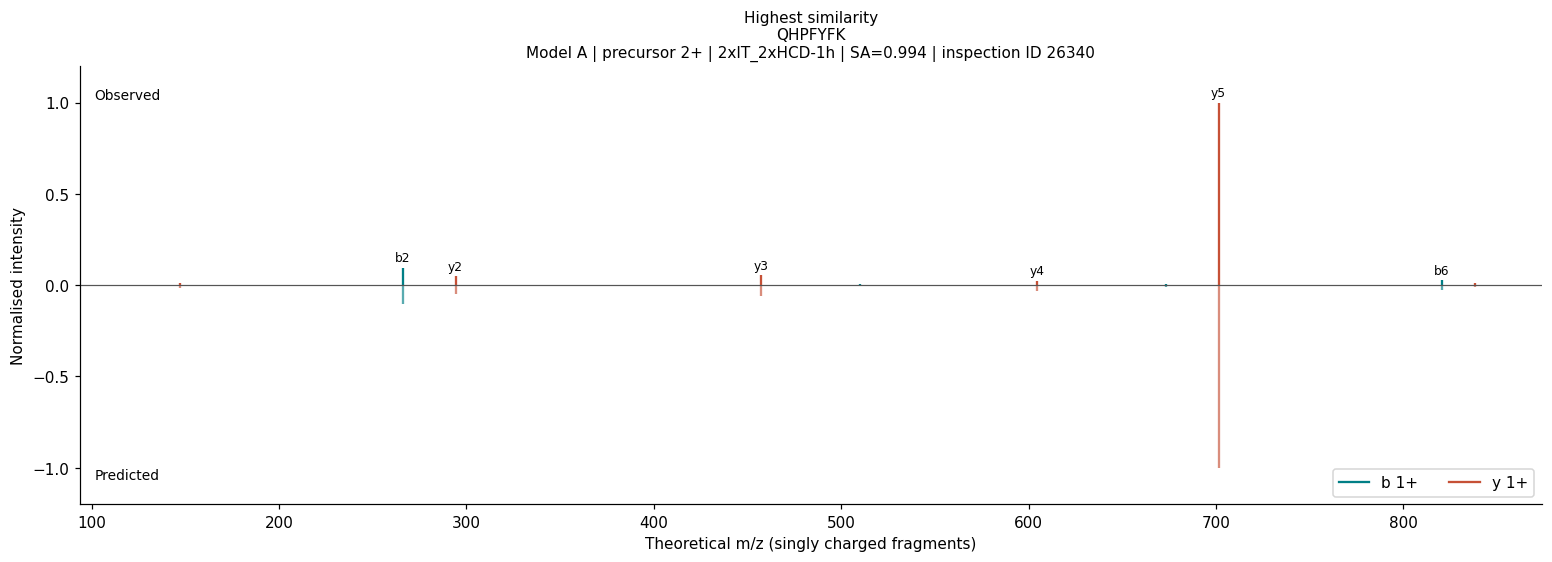

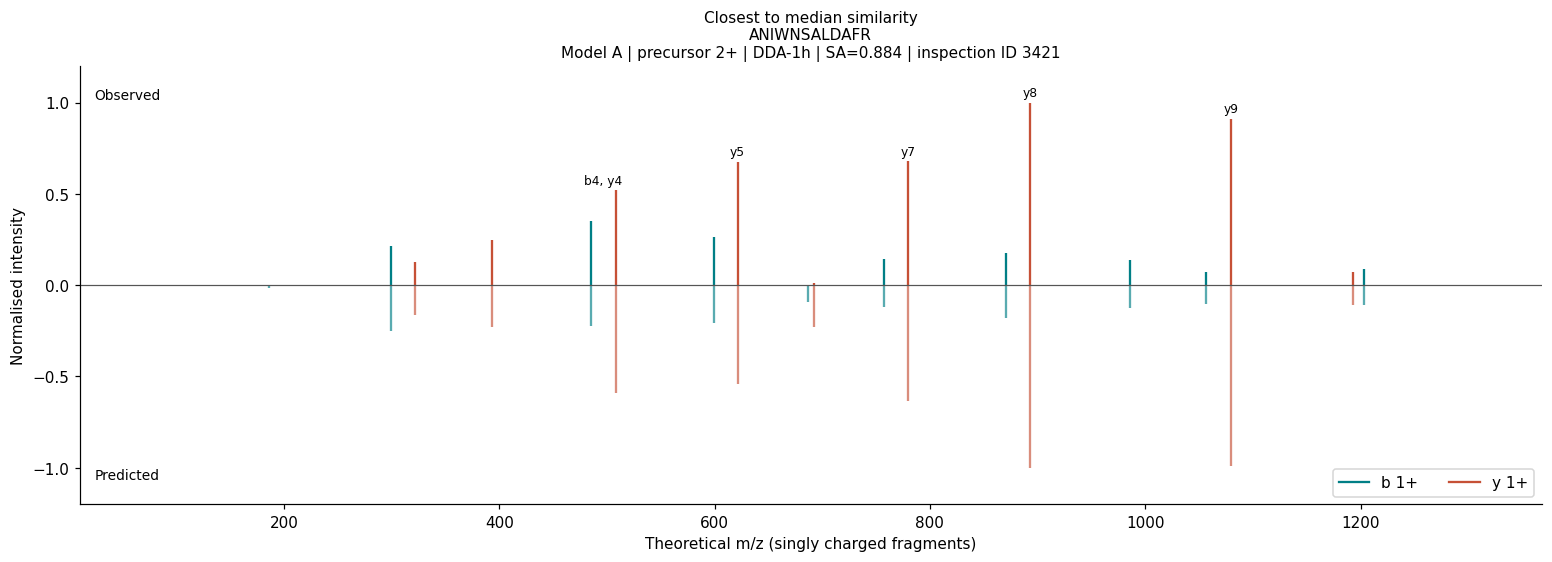

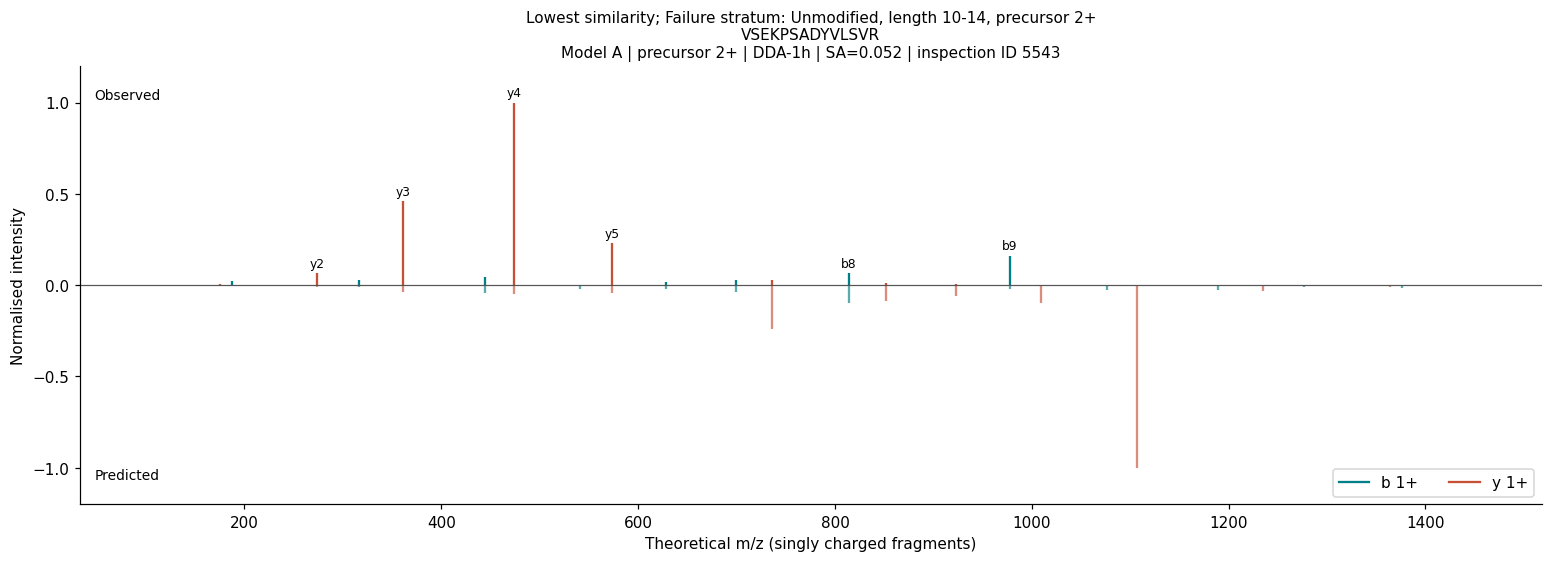

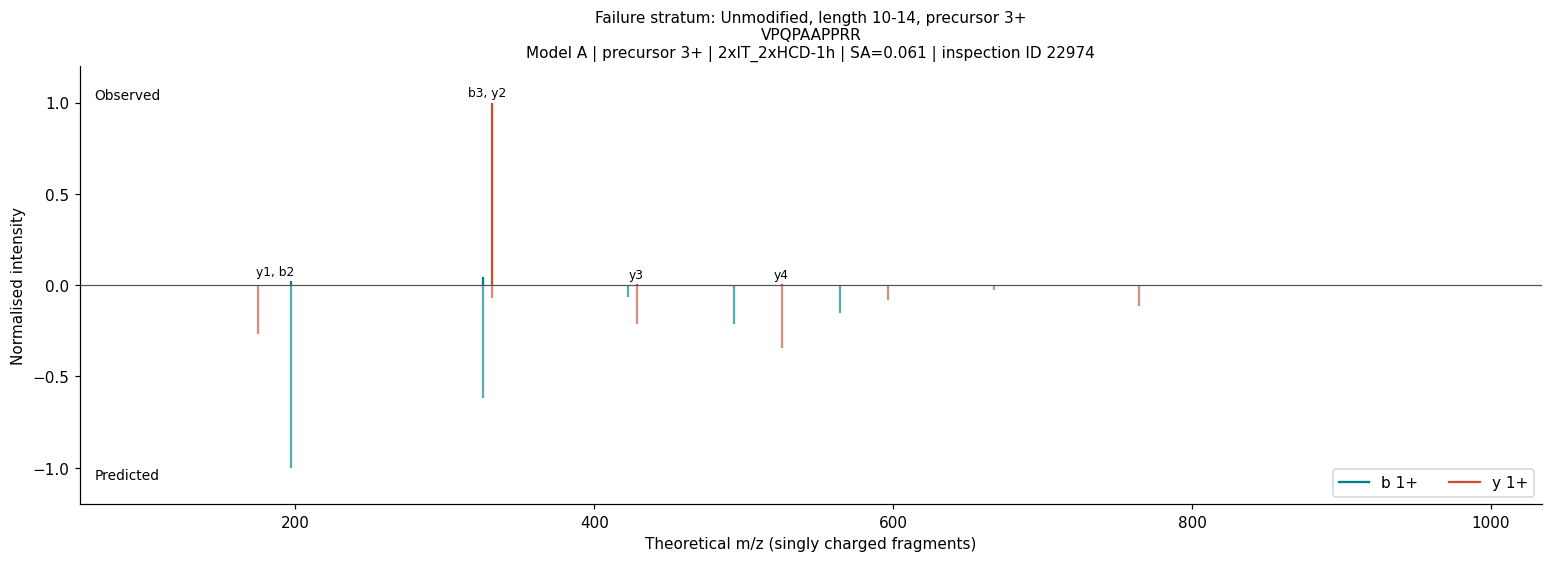

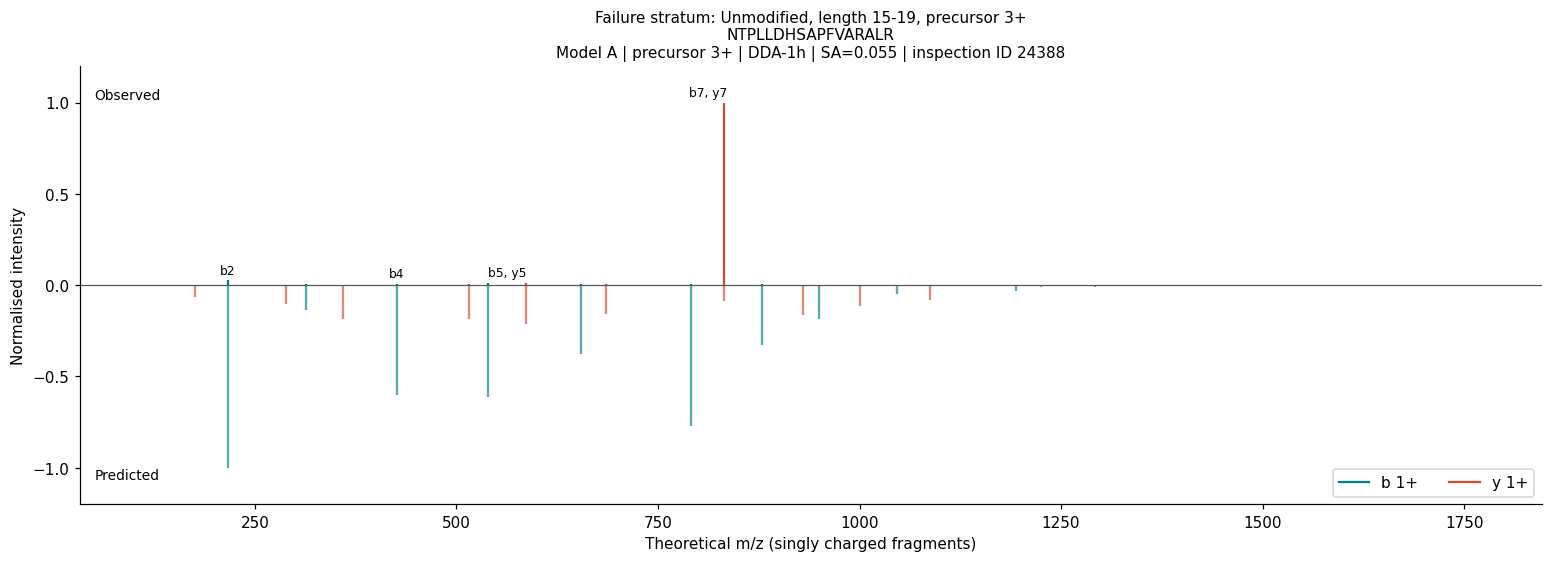

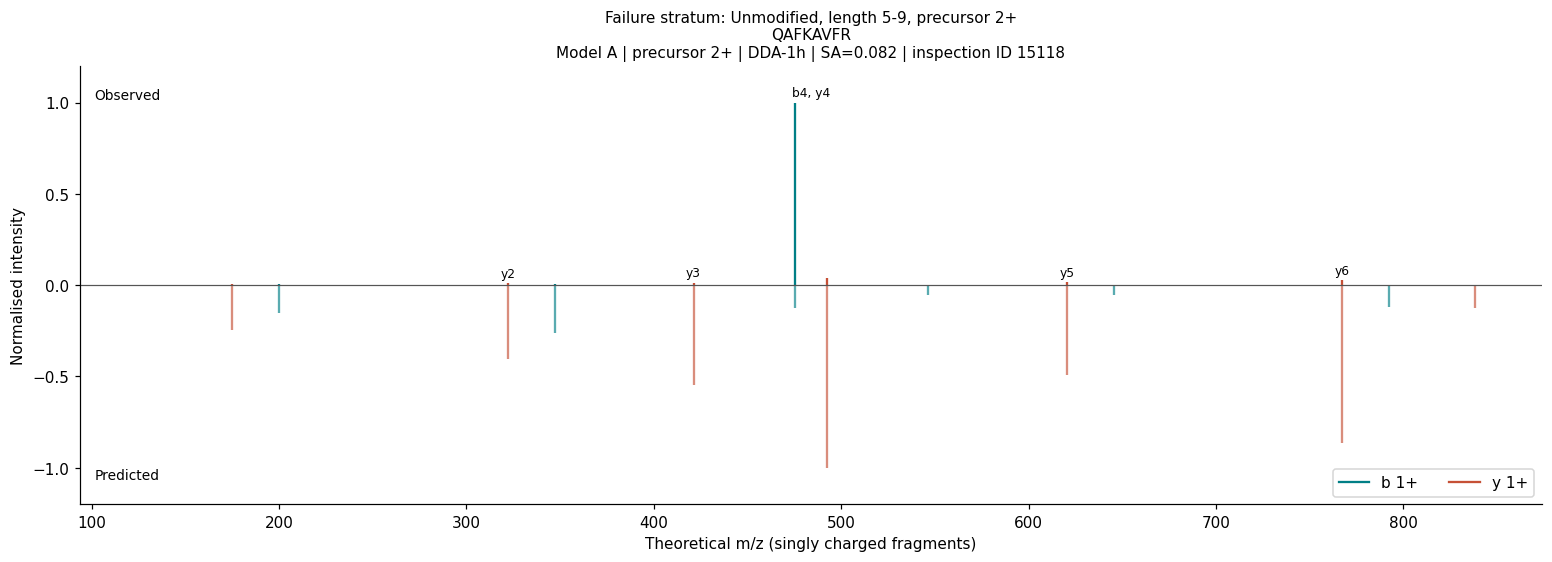

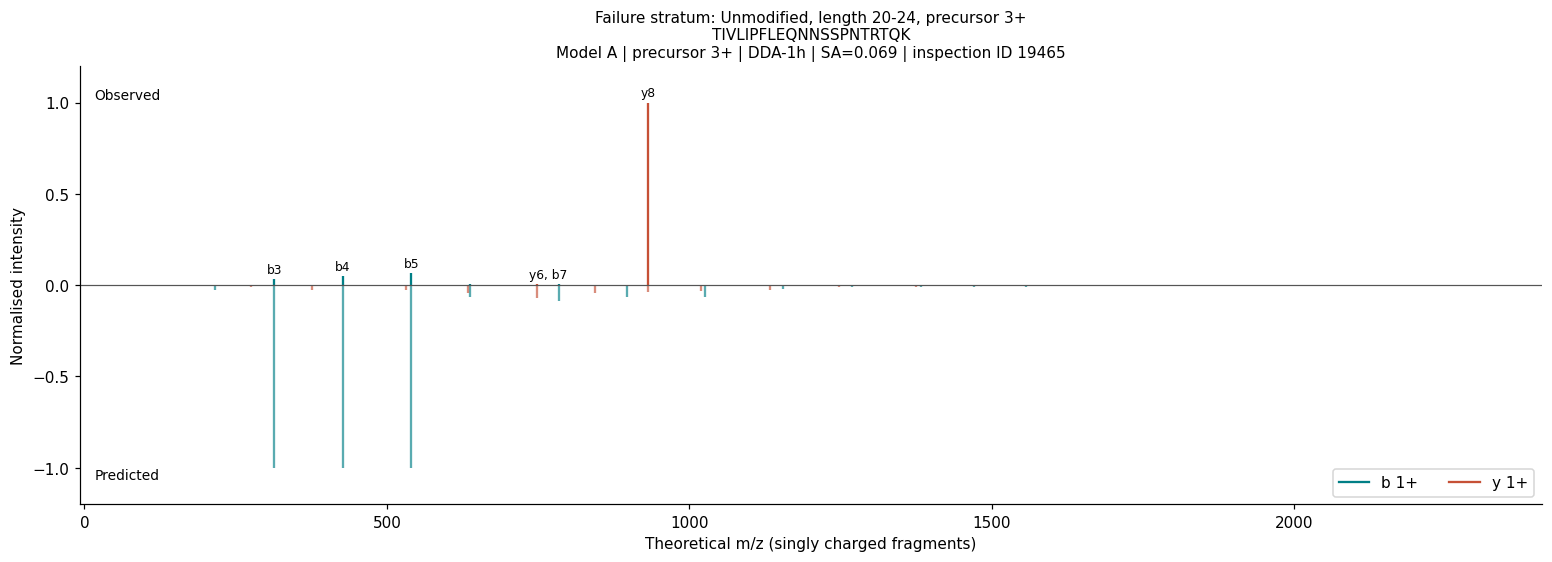

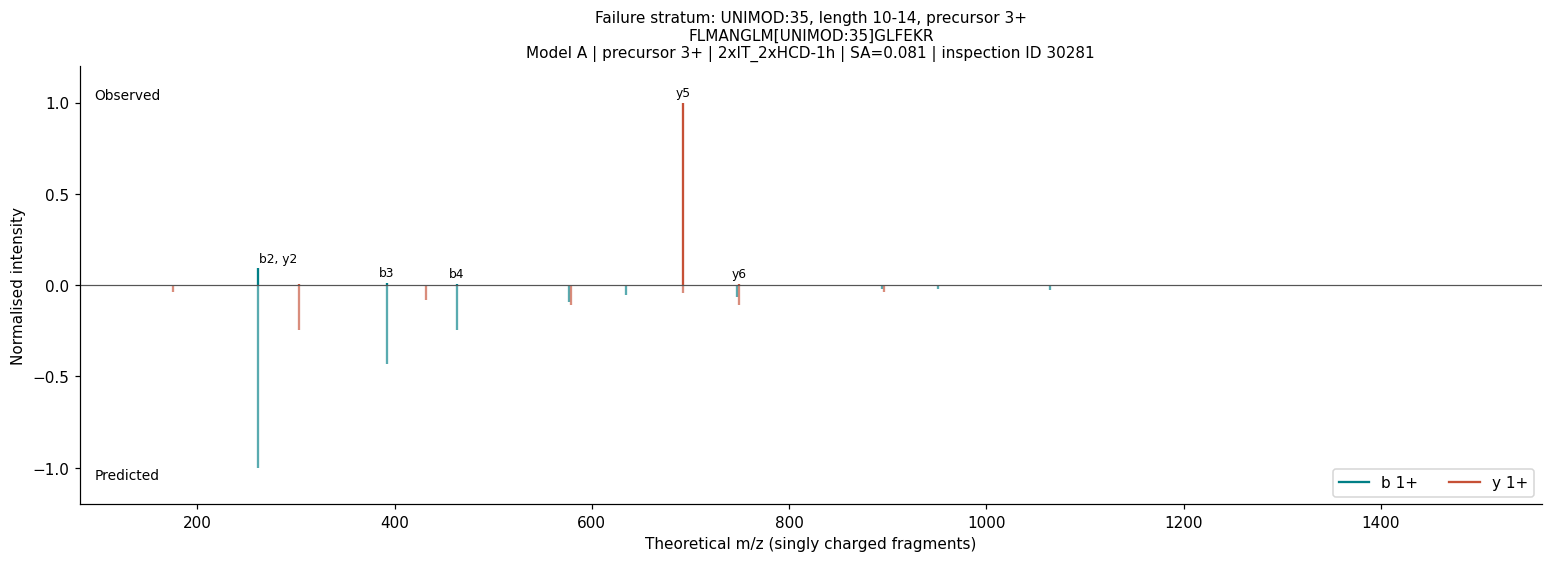

All results are validation diagnostics, not independent or CID-certified performance estimates.


In [ ]:
import textwrap
from matplotlib.lines import Line2D

MAX_FAILURE_STRATA = 6
EXTRA_SPECTRUM_IDS = []
PROTON_MASS = 1.007276466621
WATER_MASS = 18.010564684
ION_COLORS = {'b': '#007f86', 'y': '#c65036'}

def theoretical_fragment_mz(sequence, slot_indices):
    tokens = c.parse_peptide(sequence)
    masses = np.array([c.AA_MONO_MASS[token[0]] + c.MOD_MASS.get(token, 0) for token in tokens])
    prefix_masses = np.cumsum(masses)
    suffix_masses = np.cumsum(masses[::-1])
    positions = []
    for slot in slot_indices:
        ion_series, number = c.slot_to_fragment(int(slot))
        if not 1 <= number < len(tokens):
            raise ValueError('Mirror plots require valid b/y slots.')
        mass = prefix_masses[number - 1] if ion_series == 'b' else suffix_masses[number - 1] + WATER_MASS
        positions.append(mass + PROTON_MASS)
    return np.asarray(positions)

chosen = []
def select_example(frame, reason, mode='worst'):
    if frame.empty:
        return
    if mode == 'best':
        index = frame['spectral_angle'].idxmax()
    elif mode == 'median':
        index = (frame['spectral_angle'] - frame['spectral_angle'].median()).abs().idxmin()
    else:
        index = frame['spectral_angle'].idxmin()
    chosen.append({'spectrum_id': int(frame.loc[index, 'spectrum_id']), 'selection': reason})

select_example(primary_metrics, 'Highest similarity', 'best')
select_example(primary_metrics, 'Closest to median similarity', 'median')
select_example(primary_metrics, 'Lowest similarity', 'worst')
stratum_keys = ['precursor_charge', 'mod_class', 'length_bucket']
failure_strata = primary_metrics.groupby(stratum_keys, observed=True).agg(
    n=('spectral_angle', 'size'), n_failed=('failed', 'sum'), failure_rate=('failed', 'mean'),
    median_sa=('spectral_angle', 'median'), p10_sa=('spectral_angle', lambda values: values.quantile(0.1))
).reset_index()
failure_strata = failure_strata[failure_strata['n_failed'] >= MIN_GROUP_N].sort_values(
    ['n_failed', 'failure_rate'], ascending=False
).head(MAX_FAILURE_STRATA)
display(failure_strata.round(3))
if failure_strata.empty:
    print('No failure strata meet the minimum failed-spectrum support threshold.')
for stratum in failure_strata.itertuples():
    frame = primary_metrics[primary_metrics['precursor_charge'].eq(stratum.precursor_charge)
                            & primary_metrics['mod_class'].eq(stratum.mod_class)
                            & primary_metrics['length_bucket'].eq(stratum.length_bucket)
                            & primary_metrics['failed']]
    label = f'Failure stratum: {stratum.mod_class}, length {stratum.length_bucket}, precursor {stratum.precursor_charge}+'
    select_example(frame, label)
for spectrum_id in EXTRA_SPECTRUM_IDS:
    if spectrum_id not in set(spectra['spectrum_id']):
        raise ValueError(f'Unknown inspection spectrum ID: {spectrum_id}')
    chosen.append({'spectrum_id': spectrum_id, 'selection': 'Manual inspection'})
example_selection = pd.DataFrame(chosen).groupby('spectrum_id', sort=False)['selection'].agg('; '.join).reset_index()
examples = example_selection.merge(primary_metrics, on='spectrum_id', validate='one_to_one')
display(examples[['selection', 'spectrum_id', 'raw_file', 'scan_number', 'peptide_sequence',
                  'precursor_charge', 'frag', 'mod_class', 'peptide_length', 'spectral_angle', 'mae']])
row_for_id = {int(spectrum_id): row_index for row_index, spectrum_id in enumerate(spectra['spectrum_id'])}
mirror_figures = []
for example in examples.itertuples():
    row_index = row_for_id[example.spectrum_id]
    valid_slots = np.flatnonzero(MASK[row_index])
    masses = theoretical_fragment_mz(example.peptide_sequence, valid_slots)
    observed = OBSERVED_NORMALIZED[row_index, valid_slots]
    predicted = PREDICTED_NORMALIZED[PRIMARY_MODEL][row_index, valid_slots]
    series = np.asarray(c.ION_TYPES)[valid_slots % c.N_ION_TYPES]
    figure, axis = plt.subplots(figsize=(14, 5), constrained_layout=True)
    for ion_series in c.ION_TYPES:
        selected = series == ion_series
        axis.vlines(masses[selected], 0, observed[selected], color=ION_COLORS[ion_series], linewidth=1.5)
        axis.vlines(masses[selected], 0, -predicted[selected], color=ION_COLORS[ion_series], linewidth=1.5, alpha=0.65)
    strongest = np.argsort(observed)[-min(6, len(observed)):]
    label_indices = strongest[np.argsort(masses[strongest])]
    label_groups = []
    min_label_spacing = max(1, float(np.ptp(masses)) * 0.035)
    for index in label_indices:
        if observed[index] <= 0:
            continue
        if label_groups and masses[index] - masses[label_groups[-1][0]] < min_label_spacing:
            label_groups[-1].append(index)
        else:
            label_groups.append([index])
    for group in label_groups:
        peak_labels = []
        for index in group:
            ion_series, number = c.slot_to_fragment(int(valid_slots[index]))
            peak_labels.append(f'{ion_series}{number}')
        axis.annotate(', '.join(peak_labels), (float(masses[group].mean()), float(observed[group].max())),
                      xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8)
    axis.axhline(0, color='#555555', linewidth=0.8)
    axis.set(xlabel='Theoretical m/z (singly charged fragments)', ylabel='Normalised intensity', ylim=(-1.2, 1.2))
    axis.text(0.01, 0.95, 'Observed', transform=axis.transAxes, va='top', fontsize=9)
    axis.text(0.01, 0.05, 'Predicted', transform=axis.transAxes, va='bottom', fontsize=9)
    title = textwrap.fill(example.selection, width=100)
    sequence_title = textwrap.fill(example.peptide_sequence, width=90)
    axis.set_title(f'{title}\n{sequence_title}\n{PRIMARY_MODEL} | precursor {example.precursor_charge}+ | '
                   f'{example.frag} | SA={example.spectral_angle:.3f} | inspection ID {example.spectrum_id}', fontsize=10)
    axis.legend(handles=[Line2D([0], [0], color=ION_COLORS[ion], label=f'{ion} 1+') for ion in c.ION_TYPES],
                loc='lower right', ncol=2)
    mirror_figures.append(figure)
    plt.show()